# Exact Finite-State Certification of Splay Subsequence Bounds with Quantum-Assisted Counterexample Search

**An executable research laboratory: exact finite-state certificates, repeatable witnesses, and honest quantum resource accounting.**

This notebook implements the proposed paired-tree approach from scratch. It studies standard **bottom-up splaying** on a fixed ordered key set, using **pre-access depth + 1** as its cost. It does not resolve dynamic optimality, establish a size-independent constant, establish publication novelty, or demonstrate a hardware quantum advantage.

**Extended edition:** compact structural potentials, counterexample refinement, exact transfer checks through size six, feature ablation, and an arbitrary-size theorem for the two-adjacent-key access family.

**Main outputs:** exact rational finite-size certificates for all sequence lengths; cycle witnesses with matching rational lower bounds; mirror-symmetry reduction; bounded-length exhaustive checks; counterexample-guided potential synthesis; ideal amplitude-amplification simulation; noise sensitivity and total-cost accounting; and larger-tree exploratory experiments.

All default experiments run offline with NumPy, SciPy, pandas, matplotlib, NetworkX, nbformat/IPython. No QPU, API key, paid service, or optional quantum SDK is required. The quantum component is a statevector simulation of a lookup phase oracle. The precomputation needed for that lookup is counted explicitly.

**Run:** Kernel → Restart & Run All. Outputs are written to `splay_outputs/` relative to the notebook's working directory. Default exact enumeration ends at **n = 5**, because the paired-state upper bound is the square of a Catalan number. Increase limits deliberately.

## 1. Research question and contribution boundaries

For the same starting tree \(T\), compare the full access sequence \(X\) with a subsequence \(Y\preceq X\):
\[
A_T(X,Y)=C_T(Y)/C_T(X),\qquad X\ne\varnothing.
\]
The research objective is to find meaningful bounds and witnesses with independently checkable evidence. Approximate monotonicity is an established route in splay research [1]; automated amortized potential synthesis also predates this notebook [2]. The integrated implementation and its measured results are research candidates requiring further literature assessment.

**Three distinct quantities:** bounded-horizon maxima, maximum repeatable cycle ratios, and all-length bounds with additive overhead. They must not be conflated. A finite-size certificate is not a uniform theorem over all \(n\).

In [1]:
from pathlib import Path
from functools import lru_cache
from fractions import Fraction
from itertools import product
from collections import deque
import json, math, time, platform, hashlib, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import scipy
from scipy.optimize import linprog
from scipy.sparse import coo_matrix
from IPython.display import display, Markdown

OUT=Path('splay_outputs'); OUT.mkdir(exist_ok=True)
SEED=20261015
rng=np.random.default_rng(SEED)
EXACT_NS=range(1,6)
plt.rcParams.update({'figure.dpi':120,'axes.spines.top':False,'axes.spines.right':False,
                     'font.size':10,'axes.grid':True,'grid.alpha':0.18})
FIGURES=[]
def savefig(name):
    fig=plt.gcf(); fig.tight_layout()
    for ext in ('png','pdf'): fig.savefig(OUT/f'{name}.{ext}',bbox_inches='tight')
    FIGURES.append(name); plt.show(); plt.close(fig)
ENV={'python':sys.version,'numpy':np.__version__,'scipy':scipy.__version__,
     'pandas':pd.__version__,'networkx':nx.__version__,'platform':platform.platform(),'seed':SEED}
print(json.dumps(ENV,indent=2))


{
  "python": "3.12.14 (main, Aug 25 2026, 14:00:49) [Clang 22.1.3 ]",
  "numpy": "2.3.5",
  "scipy": "1.17.0",
  "pandas": "2.2.3",
  "networkx": "3.7",
  "platform": "Linux-6.18.55-x86_64-with-glibc2.39",
  "seed": 20261015
}


## 2. Cost model and exact transition engine

A tree is an immutable tuple \((k,L,R)\); the empty tree is `None`. Keys are \(0,\ldots,n-1\), preserving order. Every access splays its key to the root by zig, zig-zig, or zig-zag rotations.

\[
 c(T,x)=\operatorname{depth}_T(x)+1,\qquad S(T,x)=\text{tree after splaying }x.
\]

This cost counts visited search nodes. Standard bottom-up splaying performs exactly `depth` rotations, so a model counting search nodes **plus rotations** has per-access cost \(2c-1\). Numerical constants depend on the convention; the notebook records both when tracing examples and does not silently transfer exact constants between conventions.

We validate the pointer implementation against a structurally different immutable implementation for **every tree and every key** through the default exact limit.

In [2]:
@lru_cache(None)
def trees(lo,hi):
    if lo>=hi: return (None,)
    return tuple((k,l,r) for k in range(lo,hi)
                 for l in trees(lo,k) for r in trees(k+1,hi))

def inorder(t):
    return inorder(t[1])+(t[0],)+inorder(t[2]) if t else ()

def balanced(lo,hi):
    if lo>=hi: return None
    k=(lo+hi)//2
    return (k,balanced(lo,k),balanced(k+1,hi))

@lru_cache(None)
def access(t,x):
    keys=inorder(t); n=len(keys)
    if keys!=tuple(range(n)) or x not in keys: raise ValueError('keys must be 0..n-1')
    left=[-1]*n; right=[-1]*n; parent=[-1]*n
    def load(z,p=-1):
        if z is None: return
        k,l,r=z; parent[k]=p
        if l: left[k]=l[0]; load(l,k)
        if r: right[k]=r[0]; load(r,k)
    load(t); root=t[0]; v=root; c=1
    while v!=x:
        v=left[v] if x<v else right[v]; c+=1
    rotations=0
    def rotate(z):
        nonlocal root,rotations
        p=parent[z]; g=parent[p]
        if left[p]==z: b=right[z]; left[p]=b; right[z]=p
        else: b=left[z]; right[p]=b; left[z]=p
        if b!=-1: parent[b]=p
        parent[p]=z; parent[z]=g
        if g==-1: root=z
        elif left[g]==p: left[g]=z
        else: right[g]=z
        rotations+=1
    while parent[x]!=-1:
        p=parent[x]; g=parent[p]
        if g==-1: rotate(x)
        elif (left[g]==p)==(left[p]==x): rotate(p); rotate(x)
        else: rotate(x); rotate(x)
    def freeze(k):
        return None if k==-1 else (k,freeze(left[k]),freeze(right[k]))
    result=freeze(root)
    assert rotations==c-1 and root==x and inorder(result)==keys
    return result,c

def ref_rotate(t,direction):
    k,l,r=t
    if direction=='R':
        a,b,c=l; return (a,b,(k,c,r))
    a,b,c=r; return (a,(k,l,b),c)

def ref_at(t,path,direction):
    if not path: return ref_rotate(t,direction)
    k,l,r=t
    return (k,ref_at(l,path[1:],direction),r) if path[0]==0 else (k,l,ref_at(r,path[1:],direction))

def reference_access(t,x):
    initial=t; c=0
    while True:
        path=[]; z=t
        while z[0]!=x:
            j=0 if x<z[0] else 1; path.append(j); z=z[j+1]
        if c==0: c=len(path)+1
        if not path: return t,c
        if len(path)==1: t=ref_at(t,(), 'R' if path[-1]==0 else 'L')
        elif path[-2]==path[-1]:
            d='R' if path[-1]==0 else 'L'
            t=ref_at(t,tuple(path[:-2]),d); t=ref_at(t,tuple(path[:-2]),d)
        else:
            t=ref_at(t,tuple(path[:-1]),'R' if path[-1]==0 else 'L')
            t=ref_at(t,tuple(path[:-2]),'R' if path[-2]==0 else 'L')

def execute(t,seq):
    trace=[]; states=[t]
    for x in seq:
        t,c=access(t,int(x)); trace.append(c); states.append(t)
    return sum(trace),trace,states

def mirror(t,n):
    return (n-1-t[0],mirror(t[2],n),mirror(t[1],n)) if t else None


286 transition comparisons and mirror-equivariance checks passed.


,sequence,keys_1_based,node_visit_cost,search_plus_rotations,trace
0,X,"(3, 4, 2, 1, 2, 3)",12,18,"[1, 2, 3, 2, 2, 2]"
1,Y,"(3, 4, 1, 2, 3)",13,21,"[1, 2, 4, 3, 3]"


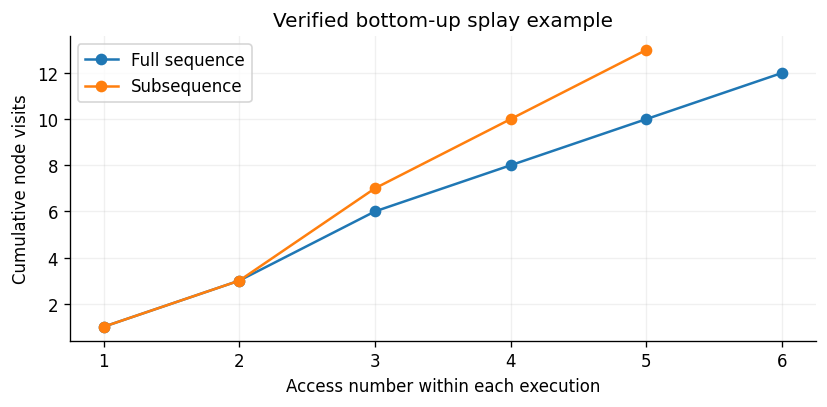

In [3]:
checks=0
for n in EXACT_NS:
    for t in trees(0,n):
        for x in range(n):
            assert access(t,x)==reference_access(t,x)
            t2,c=access(t,x)
            assert access(mirror(t,n),n-1-x)==(mirror(t2,n),c)
            checks+=1
print(f'{checks:,} transition comparisons and mirror-equivariance checks passed.')
# Reproduce the conversation example, converting labels 1..4 to 0..3.
T0=balanced(0,4)
X=(2,3,1,0,1,2); Y=(2,3,0,1,2)
cx,tx,sx=execute(T0,X); cy,ty,sy=execute(T0,Y)
assert (cx,cy)==(12,13) and sx[-1]==sy[-1]==T0
example=pd.DataFrame({'sequence':['X','Y'],'keys_1_based':[str(tuple(x+1 for x in X)),str(tuple(x+1 for x in Y))],
                      'node_visit_cost':[cx,cy],'search_plus_rotations':[2*cx-len(X),2*cy-len(Y)],
                      'trace':[str(tx),str(ty)]})
display(example); example.to_csv(OUT/'example.csv',index=False)
fig,ax=plt.subplots(figsize=(7,3.5))
for trace,label in [(tx,'Full sequence'),(ty,'Subsequence')]: ax.plot(range(1,len(trace)+1),np.cumsum(trace),'o-',label=label)
ax.set(xlabel='Access number within each execution',ylabel='Cumulative node visits',title='Verified bottom-up splay example'); ax.legend()
savefig('F01_example_costs')


## 3. Paired-tree graph and correspondence theorem

For \(s=(T_X,T_Y)\), key \(x\), and decision \(d\in\{0,1\}\):
\[
 T_X'=S(T_X,x),\quad
 T_Y'=\begin{cases}S(T_Y,x)&d=1\\T_Y&d=0,\end{cases}\quad
 a_e=c(T_X,x)>0,\quad b_e=d\,c(T_Y,x).
\]

**Path correspondence.** Starting at \((T,T)\), read edge keys to obtain \(X\), and retain those with \(d=1\) to obtain \(Y\). Induction on the path length proves that the pair of states equals the two actual executions and that the accumulated weights equal their costs. Conversely, every sequence and deletion mask induces exactly such a path.

We retain the union of states reachable from **all diagonal starting states**, covering every initial tree on these keys. Edges retain distinct action labels even if their endpoints coincide. If \(C_n=\frac1{n+1}\binom{2n}{n}\), then \(|V|\le C_n^2\) and \(|E|=2n|V|\). This is finite but grows exponentially in \(n\); no polynomial-time breakthrough is claimed.

In [4]:
def build_graph(n):
    ts=trees(0,n); ti={t:i for i,t in enumerate(ts)}; N=len(ts)
    nxt=np.empty((N,n),dtype=int); cost=np.empty((N,n),dtype=int)
    for i,t in enumerate(ts):
        for x in range(n):
            z,c=access(t,x); nxt[i,x]=ti[z]; cost[i,x]=c
    states=[(i,i) for i in range(N)]; ids={s:i for i,s in enumerate(states)}
    edges=[]; parent=[None]*N; pos=0
    while pos<len(states):
        i,j=states[pos]
        for x in range(n):
            for keep in (0,1):
                z=(int(nxt[i,x]),int(nxt[j,x]) if keep else j)
                if z not in ids:
                    ids[z]=len(states); states.append(z); parent.append(len(edges))
                edges.append((pos,ids[z],int(cost[i,x]),int(cost[j,x]) if keep else 0,x,keep))
        pos+=1
    return {'n':n,'trees':ts,'states':states,'edges':np.array(edges,dtype=np.int64),
            'parent':parent,'diagonal':list(range(N)),'nxt':nxt,'cost':cost}

def solve_potential(g,edge_ids=None):
    E=g['edges']; V=len(g['states'])
    if edge_ids is not None: E=E[np.array(edge_ids,dtype=int)]
    m=len(E); rr=np.repeat(np.arange(m),3)
    cc=np.column_stack([np.zeros(m,dtype=int),1+E[:,0],1+E[:,1]]).ravel()
    vv=np.column_stack([-E[:,2],-np.ones(m),np.ones(m)]).ravel()
    A=coo_matrix((vv,(rr,cc)),shape=(m,V+1)).tocsr()
    objective=np.zeros(V+1); objective[0]=1
    fit=linprog(objective,A_ub=A,b_ub=-E[:,3],bounds=[(0,g['n'])]+[(None,None)]*V,method='highs')
    if not fit.success: raise RuntimeError(fit.message)
    return fit.x[0],fit.x[1:]

def exact_certificate(g,K):
    # Integer longest-path inequalities. If no positive-weight cycle exists,
    # a maximizing walk can have all repeated-vertex cycles removed.
    E=g['edges']; u,v,a,b=E[:,:4].T; V=len(g['states'])
    p,q=K.numerator,K.denominator; w=q*b-p*a
    H=np.zeros(V,dtype=np.int64)
    for iteration in range(V):
        new=H.copy(); np.maximum.at(new,v,H[u]+w)
        if np.array_equal(new,H):
            slack=H[v]-H[u]-w
            assert int(slack.min())>=0
            return H,slack,iteration
        H=new
    raise ValueError('Candidate K lacks an exact certificate: positive cycle or insufficient rational precision')

def tight_cycle(g,K,H):
    E=g['edges']; p,q=K.numerator,K.denominator
    graph=nx.DiGraph()
    for eid,(u,v,a,b,x,d) in enumerate(E):
        if H[v]-H[u]==q*b-p*a: graph.add_edge(int(u),int(v),eid=eid)
    try: cyc=nx.find_cycle(graph)
    except nx.NetworkXNoCycle: raise ValueError('No tight cycle: candidate is not proven optimal')
    ids=[graph[u][v]['eid'] for u,v in cyc]
    e=E[ids]; assert Fraction(int(e[:,3].sum()),int(e[:,2].sum()))==K
    return ids

def prefix_to(g,state):
    ids=[]
    while g['parent'][state] is not None:
        eid=g['parent'][state]; ids.append(eid); state=int(g['edges'][eid,0])
    return list(reversed(ids)),state


## 4. Exact finite-size theorem and primal–dual evidence

For a rational candidate \(K=p/q\), define integer edge weights
\[
 w_e=q b_e-p a_e.
\]
A certificate assigns integers \(H(s)\) with
\[
 H(v)-H(u)\ge w_e\quad\text{on every edge }e:u\to v.
\]
Summing gives, for **every path length**,
\[
 C_T(Y)\le K C_T(X)+\frac{H(s_f)-H(s_0)}q
 \le K C_T(X)+B_T,
\quad B_T=\frac{\max_sH(s)-H((T,T))}{q}.
\]
Equivalently use \(\Phi=-H/q\) in the potential inequality proposed earlier.

A reachable cycle with \(\sum b_e/\sum a_e=K\) proves that no smaller coefficient can work with a fixed additive allowance: repeat it after a fixed prefix. Together, the exact potential and a matching cycle certify the **optimal asymptotic coefficient for this finite graph**.

**Why certificates exist:** if every cycle has nonpositive \(w\)-weight, remove repeated-vertex cycles from a maximizing walk without decreasing its weight. Longest walks are therefore represented by simple paths of at most \(|V|-1\) edges. Bellman-style relaxation from zero constructs an integer \(H\). A positive cycle makes the inequalities impossible by summation.

The LP only proposes \(K\). Floating-point solver status is **never** accepted as proof: rational reconstruction, all-edge integer verification, and a matching cycle are mandatory. Failures raise errors. Arithmetic overflow is guarded for default sizes.

In [5]:
GRAPHS={}; CERTS={}; rows=[]
for n in EXACT_NS:
    start=time.perf_counter(); g=build_graph(n); build_s=time.perf_counter()-start
    start=time.perf_counter(); kfloat,phi=solve_potential(g); lp_s=time.perf_counter()-start
    K=Fraction(float(kfloat)).limit_denominator(1_000_000)
    assert K.denominator*n*len(g['states'])*4 < np.iinfo(np.int64).max
    start=time.perf_counter(); H,slack,it=exact_certificate(g,K); cycle=tight_cycle(g,K,H)
    cert_s=time.perf_counter()-start
    B=max(Fraction(int(H.max()-H[s]),K.denominator) for s in g['diagonal'])
    GRAPHS[n]=g; CERTS[n]={'K':K,'H':H,'slack':slack,'cycle':cycle,'B':B}
    payload={'n':n,'K':[K.numerator,K.denominator], 'H':H.tolist(),
             'states':[list(s) for s in g['states']], 'edges':g['edges'].tolist(),
             'cycle_edge_ids':[int(e) for e in cycle], 'diagonal_state_ids':g['diagonal'],
             'cost_model':'bottom-up splay; pre-access depth plus one'}
    (OUT/f'certificate_n{n}.json').write_text(json.dumps(payload),encoding='utf-8')
    rows.append({'n':n,'trees':len(g['trees']),'states':len(g['states']),'edges':len(g['edges']),
                 'K_exact':str(K),'K':float(K),'B_max':float(B),'cycle_length':len(cycle),
                 'minimum_integer_slack':int(slack.min()),'relaxation_passes':it,
                 'build_s':build_s,'LP_s':lp_s,'exact_check_s':cert_s})
summary=pd.DataFrame(rows); display(summary)
summary.to_csv(OUT/'finite_size_certificates.csv',index=False)
print('Every reported K has an exact all-edge upper certificate and an equal-ratio reachable cycle.')


Every reported K has an exact all-edge upper certificate and an equal-ratio reachable cycle.


,n,trees,states,edges,K_exact,K,B_max,cycle_length,minimum_integer_slack,relaxation_passes,build_s,LP_s,exact_check_s
0,1,1,1,2,1,1.0,0.0,1,0,0,0.000041,0.004292,0.000900
1,2,2,4,16,1,1.0,0.0,1,0,1,0.000046,0.002545,0.000309
2,3,5,19,114,1,1.0,1.0,1,0,1,0.000243,0.002468,0.000354
3,4,14,196,1568,3/2,1.5,2.0,2,0,3,0.002088,0.009523,0.002455
4,5,42,1764,17640,8/5,1.6,3.0,4,0,4,0.018936,0.492384,0.029074


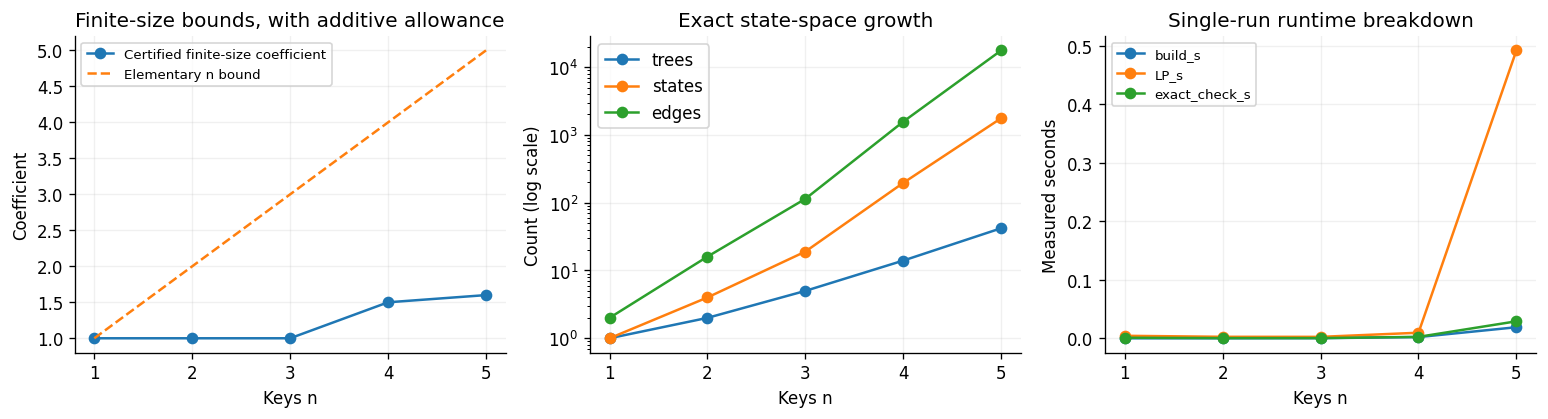

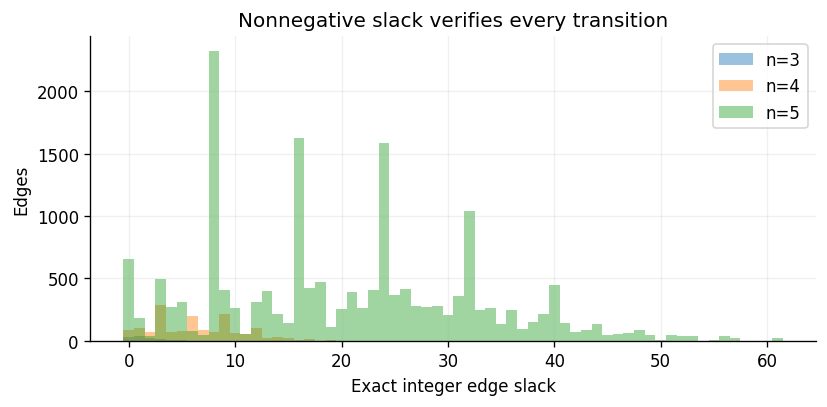

In [6]:
fig,axes=plt.subplots(1,3,figsize=(13,3.6))
axes[0].plot(summary.n,summary.K,'o-',label='Certified finite-size coefficient')
axes[0].plot(summary.n,summary.n,'--',label='Elementary n bound'); axes[0].legend(fontsize=8)
axes[0].set(xlabel='Keys n',ylabel='Coefficient',title='Finite-size bounds, with additive allowance')
for col in ['trees','states','edges']: axes[1].semilogy(summary.n,summary[col],'o-',label=col)
axes[1].set(xlabel='Keys n',ylabel='Count (log scale)',title='Exact state-space growth'); axes[1].legend()
for col in ['build_s','LP_s','exact_check_s']: axes[2].plot(summary.n,summary[col],'o-',label=col)
axes[2].set(xlabel='Keys n',ylabel='Measured seconds',title='Single-run runtime breakdown'); axes[2].legend(fontsize=8)
savefig('F02_certificates_scaling')
fig,ax=plt.subplots(figsize=(7,3.5))
for n in (3,4,5):
    vals=CERTS[n]['slack']; ax.hist(vals,bins=np.arange(vals.max()+2)-.5,alpha=.45,label=f'n={n}')
ax.set(xlabel='Exact integer edge slack',ylabel='Edges',title='Nonnegative slack verifies every transition'); ax.legend()
savefig('F03_certificate_slack')


## 5. Witness extraction and infinite repetition

A cycle may begin away from a diagonal state. We retain a BFS prefix from a diagonal to its start. For prefix costs \((A_0,B_0)\) and cycle costs \((A_c,B_c)\),
\[
 R_r=\frac{B_0+rB_c}{A_0+rA_c}\longrightarrow\frac{B_c}{A_c}=K_n.
\]
This is a rigorous infinite family for a **fixed** \(n\), not a family establishing unbounded ratios as \(n\to\infty\). We replay the extracted actions through the splay engine and check cycle closure.

,n,prefix_length,cycle_length,A0,B0,Ac,Bc,ratio
0,3,0,1,0,0,1,1,1
1,4,2,2,8,2,4,6,3/2
2,5,3,4,10,3,10,16,8/5


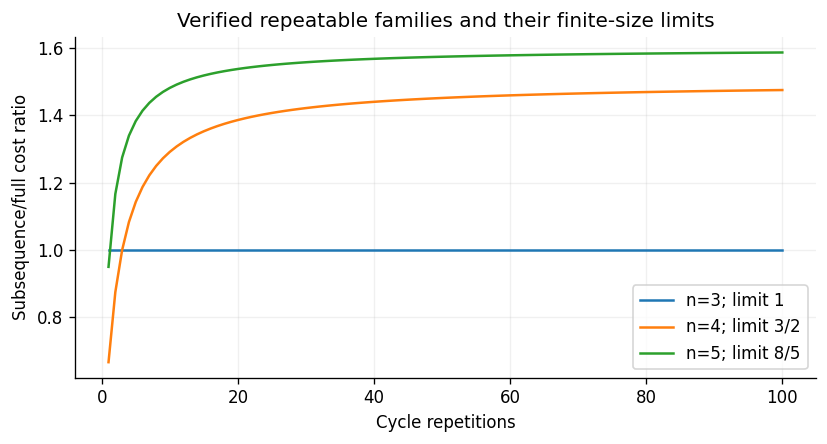

In [7]:
witness_rows=[]; witness_payload=[]
fig,ax=plt.subplots(figsize=(7,3.8))
for n in (3,4,5):
    g=GRAPHS[n]; cert=CERTS[n]; E=g['edges']; cyc=cert['cycle']; start=int(E[cyc[0],0])
    prefix,diag=prefix_to(g,start)
    A0=int(E[prefix,2].sum()) if prefix else 0; B0=int(E[prefix,3].sum()) if prefix else 0
    Ac=int(E[cyc,2].sum()); Bc=int(E[cyc,3].sum())
    full=prefix+cyc*3
    Xw=tuple(int(E[e,4]) for e in full)
    Yw=tuple(int(E[e,4]) for e in full if E[e,5])
    ti=g['states'][diag][0]; t=g['trees'][ti]
    xa,_,xs=execute(t,Xw); yb,_,ys=execute(t,Yw)
    assert xa==A0+3*Ac and yb==B0+3*Bc
    # Check every cycle transition and exact return of the paired state.
    state=start
    for eid in cyc:
        assert state==E[eid,0]; state=int(E[eid,1])
    assert state==start
    r=np.arange(1,101); ax.plot(r,(B0+r*Bc)/(A0+r*Ac),label=f'n={n}; limit {cert["K"]}')
    witness_rows.append({'n':n,'prefix_length':len(prefix),'cycle_length':len(cyc),'A0':A0,'B0':B0,'Ac':Ac,'Bc':Bc,'ratio':str(Fraction(Bc,Ac))})
    witness_payload.append({'n':n,'initial_tree':t,'prefix_actions':E[prefix,4:6].tolist(),
                            'cycle_actions':E[cyc,4:6].tolist(),'cycle_costs':[Ac,Bc]})
display(pd.DataFrame(witness_rows))
pd.DataFrame(witness_rows).to_csv(OUT/'cycle_witnesses.csv',index=False)
(OUT/'cycle_witnesses.json').write_text(json.dumps(witness_payload),encoding='utf-8')
ax.set(xlabel='Cycle repetitions',ylabel='Subsequence/full cost ratio',title='Verified repeatable families and their finite-size limits'); ax.legend()
savefig('F04_cycle_repetition')


## 6. Bounded-horizon experiment and cross-check

For the balanced four-key tree and length six, exhaust every sequence and nonempty deletion mask. A deletion mask denotes positions, so different masks can produce identical subsequence values. Counts below are **encoded candidates**, not counts of distinct subsequences.

The bounded-horizon maximum need not equal the asymptotic cycle coefficient: a finite path can carry transient cost. We check every candidate against the exact potential inequality using its actual final paired state.

{'candidate_pairs': 258048, 'maximum': '13/12', 'marked_above_one': 81, 'seconds': 1.1233722849999594}
One maximizing sequence (1-based), mask, full cost, subsequence cost: (4, 2, 1, 1, 2, 3) (61, 12, 13)


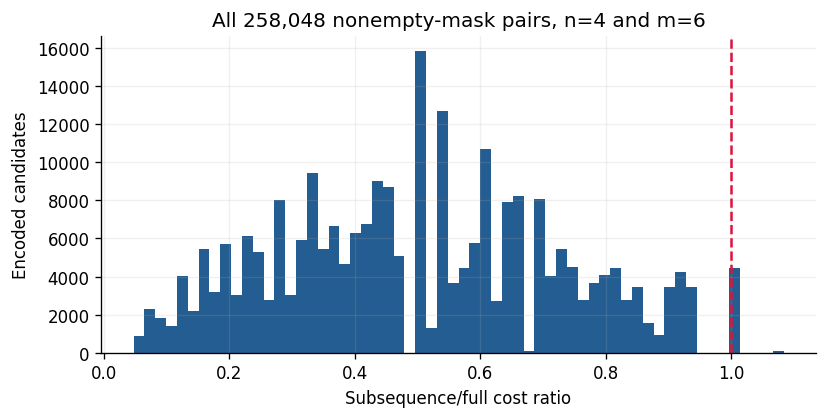

In [8]:
g=GRAPHS[4]; ts=g['trees']; ti={t:i for i,t in enumerate(ts)}; ids={s:i for i,s in enumerate(g['states'])}
nxt,cost=g['nxt'],g['cost']; init=ti[T0]; q=CERTS[4]['K'].denominator; p=CERTS[4]['K'].numerator; H=CERTS[4]['H']
ratios=[]; maximum=Fraction(0); best=None; marked=np.zeros(2**18,dtype=bool)
start=time.perf_counter()
for sid in range(4**6):
    seq=tuple((sid>>(2*j))&3 for j in range(6)); i=init; a=0
    for x in seq: a+=int(cost[i,x]); i=int(nxt[i,x])
    for mask in range(1,64):
        j=init; b=0
        for pos,x in enumerate(seq):
            if (mask>>pos)&1: b+=int(cost[j,x]); j=int(nxt[j,x])
        assert q*b-p*a <= int(H[ids[(i,j)]]-H[ids[(init,init)]])
        ratio=Fraction(b,a); ratios.append(float(ratio)); marked[sid*64+mask]=b>a
        if ratio>maximum: maximum=ratio; best=(seq,mask,a,b)
exhaustive_s=time.perf_counter()-start
assert maximum==Fraction(13,12) and int(marked.sum())==81
print({'candidate_pairs':len(ratios),'maximum':str(maximum),'marked_above_one':int(marked.sum()),'seconds':exhaustive_s})
print('One maximizing sequence (1-based), mask, full cost, subsequence cost:',tuple(x+1 for x in best[0]),best[1:])
fig,ax=plt.subplots(figsize=(7,3.6)); ax.hist(ratios,bins=60,color='#245d91')
ax.axvline(1,color='crimson',ls='--'); ax.set(xlabel='Subsequence/full cost ratio',ylabel='Encoded candidates',title='All 258,048 nonempty-mask pairs, n=4 and m=6')
savefig('F05_bounded_ratio_distribution')


## 7. Mirror-symmetry quotient with verification

Reflecting both trees and replacing \(x\) by \(n-1-x\) preserves transitions, decisions, and both costs. We quotient each state with its simultaneous reflection. Action-labelled quotient edges are deduplicated only when source, destination, **both costs**, and keep/delete decision agree; the key label is unnecessary for the upper-bound LP.

An upper certificate on the quotient lifts by assigning the same potential to each orbit member. We verify every original edge after lifting. The reduction is at most a factor of two and does not remove exponential dependence on \(n\).

,n,original_states,quotient_states,original_edges,quotient_edges,same_exact_K
0,3,19,10,114,58,1
1,4,196,98,1568,784,3/2
2,5,1764,884,17640,8824,8/5


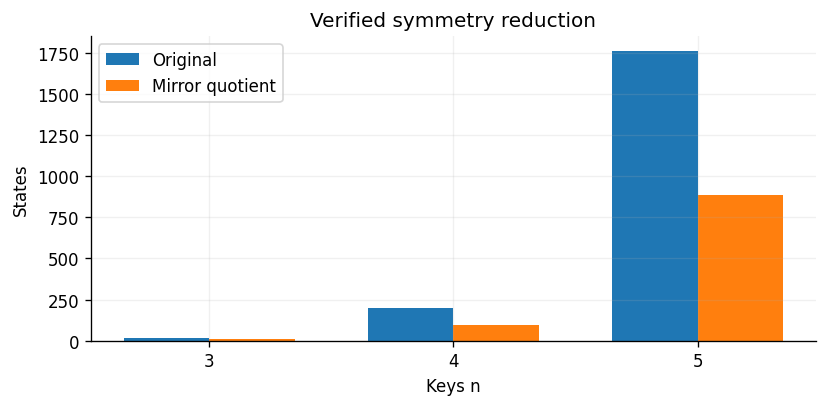

In [9]:
symmetry_rows=[]
for n in (3,4,5):
    g=GRAPHS[n]; ti={t:i for i,t in enumerate(g['trees'])}; state_ids={s:i for i,s in enumerate(g['states'])}
    orbit_keys=[]
    for i,j in g['states']:
        m=(ti[mirror(g['trees'][i],n)],ti[mirror(g['trees'][j],n)])
        assert m in state_ids
        orbit_keys.append(min((i,j),m))
    oi={key:i for i,key in enumerate(sorted(set(orbit_keys)))}; lift=np.array([oi[k] for k in orbit_keys])
    reduced=set()
    for u,v,a,b,x,d in g['edges']: reduced.add((int(lift[u]),int(lift[v]),int(a),int(b),0,int(d)))
    qg={'n':n,'states':list(oi),'edges':np.array(sorted(reduced),dtype=np.int64)}
    kf,_=solve_potential(qg); K=Fraction(float(kf)).limit_denominator(1_000_000)
    Hq,_,_=exact_certificate(qg,K); e=g['edges']; Hl=Hq[lift]
    assert np.all(Hl[e[:,1]]-Hl[e[:,0]] >= K.denominator*e[:,3]-K.numerator*e[:,2])
    assert K==CERTS[n]['K']
    symmetry_rows.append({'n':n,'original_states':len(g['states']),'quotient_states':len(oi),
                          'original_edges':len(e),'quotient_edges':len(reduced),'same_exact_K':str(K)})
symmetry=pd.DataFrame(symmetry_rows); display(symmetry); symmetry.to_csv(OUT/'symmetry_reduction.csv',index=False)
fig,ax=plt.subplots(figsize=(7,3.5)); x=np.arange(len(symmetry)); w=.35
ax.bar(x-w/2,symmetry.original_states,w,label='Original'); ax.bar(x+w/2,symmetry.quotient_states,w,label='Mirror quotient')
ax.set_xticks(x,symmetry.n); ax.set(xlabel='Keys n',ylabel='States',title='Verified symmetry reduction'); ax.legend()
savefig('F06_symmetry_reduction')


## 8. Counterexample-guided potential synthesis (CEGIS)

Start with a small deterministic random subset of edge constraints. Solve for \(K\) and a potential, inspect all omitted edges, and add violated constraints. Terminate only after a full scan finds no residual above numerical tolerance. This experiment is classical constraint generation; quantum search is evaluated separately as a hypothetical replacement for violation discovery.

For an edge set of size \(E\) with \(M>0\) violations, amplitude amplification requires order \(\sqrt{E/M}\) predicate calls in an ideal query model. Counting violations to choose an ideal iteration count is itself work: here it is obtained from the classical scan and is **not free**. Unknown-marked-count search would need an adaptive schedule and additional failure accounting.

,iteration,active_edges,K_proposed,violations,max_residual,LP_s,classical_scan_calls,ideal_query_scale
0,0,20,1.0,311,7.0,0.004940,1568,2.245395
1,1,148,1.0,151,5.0,0.004726,1568,3.222438
2,2,276,1.5,114,7.0,0.003809,1568,3.708691
3,3,390,1.5,23,2.0,0.004092,1568,8.256750
4,4,413,1.5,5,1.5,0.004163,1568,17.708755
5,5,418,1.5,4,0.5,0.003775,1568,19.798990
6,6,422,1.5,4,1.0,0.003553,1568,19.798990
7,7,426,1.5,0,0.0,0.003983,1568,NaN


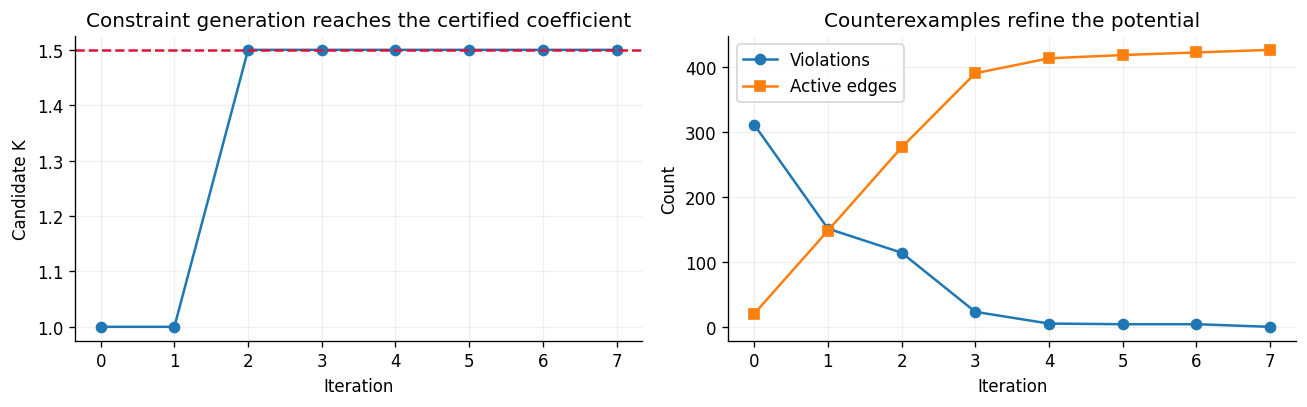

In [10]:
g=GRAPHS[4]; E=g['edges']; V=len(g['states']); m=len(E)
active=set(rng.choice(m,size=min(20,m),replace=False).tolist()); cegis=[]; violation_masks=[]
for iteration in range(m+1):
    t=time.perf_counter(); K,phi=solve_potential(g,sorted(active)); fit_s=time.perf_counter()-t
    residual=E[:,3]-K*E[:,2]-phi[E[:,0]]+phi[E[:,1]]
    bad=np.flatnonzero(residual>1e-7)
    violation_masks.append(residual>1e-7)
    cegis.append({'iteration':iteration,'active_edges':len(active),'K_proposed':K,'violations':len(bad),
                  'max_residual':float(residual.max()),'LP_s':fit_s,'classical_scan_calls':m,
                  'ideal_query_scale':math.sqrt(m/len(bad)) if len(bad) else np.nan})
    if not len(bad): break
    chosen=bad[np.argsort(residual[bad])[-min(128,len(bad)):]]
    before=len(active); active.update(chosen.tolist()); assert len(active)>before
else: raise RuntimeError('CEGIS did not converge')
Kcheck=Fraction(float(K)).limit_denominator(1_000_000)
Hcheck,_,_=exact_certificate(g,Kcheck); assert Kcheck==CERTS[4]['K']
cegis=pd.DataFrame(cegis); display(cegis); cegis.to_csv(OUT/'cegis_iterations.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(11,3.5))
axes[0].plot(cegis.iteration,cegis.K_proposed,'o-'); axes[0].axhline(float(CERTS[4]['K']),ls='--',color='crimson')
axes[0].set(xlabel='Iteration',ylabel='Candidate K',title='Constraint generation reaches the certified coefficient')
axes[1].plot(cegis.iteration,cegis.violations,'o-',label='Violations'); axes[1].plot(cegis.iteration,cegis.active_edges,'s-',label='Active edges')
axes[1].set(xlabel='Iteration',ylabel='Count',title='Counterexamples refine the potential'); axes[1].legend()
savefig('F07_cegis')


### 8.1 Quantum search on the actual CEGIS violation tables

To connect the two components directly, simulate an edge-index phase oracle for each nonterminal CEGIS iteration. Pad the edge domain to a power of two and mark exactly the violations found in that iteration. Invalid padded entries remain unmarked. An independently seeded measurement selects an edge, and a classical lookup verifies that it is a violation. This uses the already computed violation table and does not replace or hide the all-edge scan used to create it. The final zero-violation iteration is certified classically; no Grover iteration count is defined for zero marked states.

,iteration,padded_domain,violations,grover_iterations,success_probability,verified_edge_id,measurement_attempts
0,0,2048,311,1,0.869286,619,1
1,1,2048,151,2,0.962125,751,1
2,2,2048,114,3,0.990726,869,1
3,3,2048,23,7,0.999525,905,1
4,4,2048,5,15,0.998523,514,1
5,5,2048,4,17,0.999448,385,1
6,6,2048,4,17,0.999448,141,1


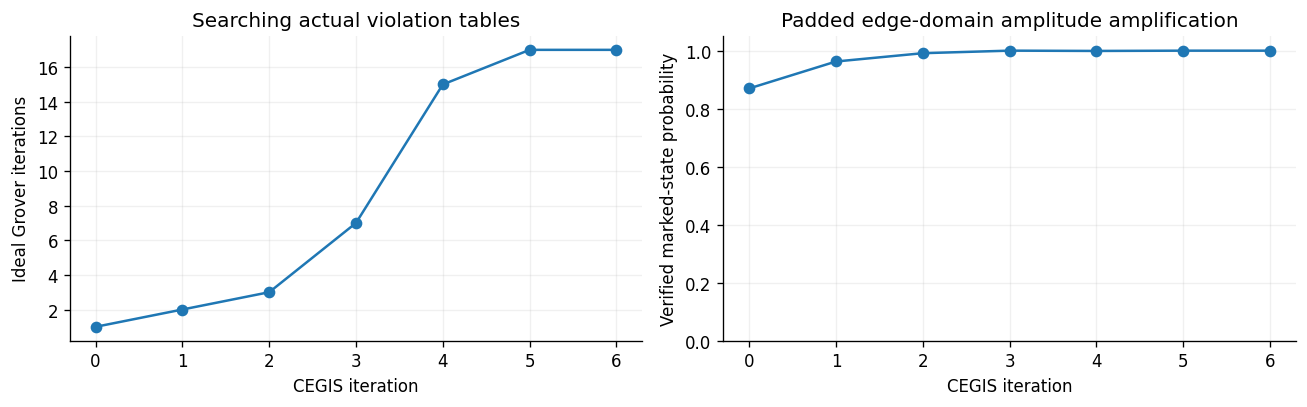

In [11]:
edge_quantum=[]; qrng=np.random.default_rng(SEED+1)
for iteration,mask in enumerate(violation_masks):
    Mv=int(mask.sum())
    if Mv==0: continue
    Nv=1<<int(math.ceil(math.log2(len(mask))))
    padded=np.zeros(Nv,dtype=bool); padded[:len(mask)]=mask
    angle=math.asin(math.sqrt(Mv/Nv)); steps=max(0,round(math.pi/(4*angle)-.5))
    state=np.full(Nv,1/math.sqrt(Nv))
    for _ in range(steps): state[padded]*=-1; state=2*state.mean()-state
    success=float(np.square(state[padded]).sum())
    assert abs(success-math.sin((2*steps+1)*angle)**2)<1e-10
    shots=0
    while True:
        shots+=1; edge=int(qrng.choice(Nv,p=np.square(state)/np.square(state).sum()))
        if edge<len(mask) and mask[edge]: break
        if shots>=100: raise RuntimeError('Unexpected repeated verification failure')
    edge_quantum.append({'iteration':iteration,'padded_domain':Nv,'violations':Mv,
                         'grover_iterations':steps,'success_probability':success,
                         'verified_edge_id':edge,'measurement_attempts':shots})
edge_quantum=pd.DataFrame(edge_quantum); display(edge_quantum)
edge_quantum.to_csv(OUT/'cegis_quantum_edge_search.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(11,3.5))
axes[0].plot(edge_quantum.iteration,edge_quantum.grover_iterations,'o-')
axes[0].set(xlabel='CEGIS iteration',ylabel='Ideal Grover iterations',title='Searching actual violation tables')
axes[1].plot(edge_quantum.iteration,edge_quantum.success_probability,'o-'); axes[1].set_ylim(0,1.05)
axes[1].set(xlabel='CEGIS iteration',ylabel='Verified marked-state probability',title='Padded edge-domain amplitude amplification')
savefig('F12_cegis_quantum_search')


## 9. Explicit quantum amplitude-amplification simulation

For \(N=2^{18}\) encoded sequence–mask states, the lookup oracle marks exactly the 81 six-access candidates with subsequence cost greater than full cost. Empty-mask states are unmarked. Initialize
\[
 |s\rangle=N^{-1/2}\sum_{z=0}^{N-1}|z\rangle,
\quad O_f|z\rangle=(-1)^{f(z)}|z\rangle,
\quad D=2|s\rangle\langle s|-I.
\]
With \(\theta=\arcsin\sqrt{M/N}\),
\[
 P_k=\sin^2((2k+1)\theta).
\]
We apply the actual phase flips and diffusion to a NumPy amplitude vector and verify against this formula and unit norm. This simulates an ideal quantum state; it is not a gate compilation or a QPU experiment. The oracle table was computed classically in Section 6.

Selecting \(k\) using the known \(M\) is an ideal calibrated experiment. We also report final classical candidate verification costs.

{
  "register_qubits": 18,
  "N": 262144,
  "M": 81,
  "iterations": 44,
  "initial_success": 0.000308990478515625,
  "ideal_final_success": 0.9999607800566782,
  "sampled_full_cost": 14,
  "sampled_subsequence_cost": 15,
  "sample_is_marked": true,
  "oracle_type": "classically precomputed phase lookup"
}


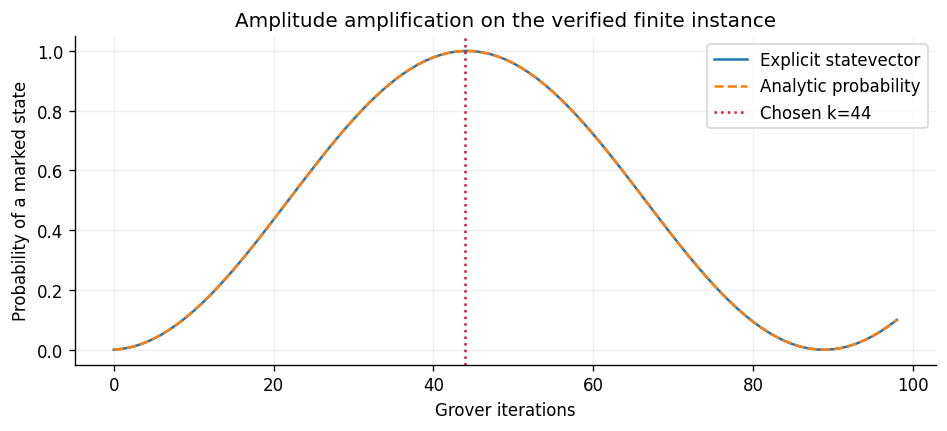

In [12]:
N=len(marked); M=int(marked.sum()); theta=math.asin(math.sqrt(M/N))
kstar=max(0,round(math.pi/(4*theta)-.5))
amp=np.full(N,1/math.sqrt(N)); probabilities=[float(np.square(amp[marked]).sum())]
for k in range(1,2*kstar+11):
    amp[marked]*=-1; amp=2*amp.mean()-amp
    prob=float(np.square(amp[marked]).sum()); probabilities.append(prob)
    assert abs(float(amp@amp)-1)<1e-10
    assert abs(prob-math.sin((2*k+1)*theta)**2)<1e-10
at_opt=np.full(N,1/math.sqrt(N))
for _ in range(kstar): at_opt[marked]*=-1; at_opt=2*at_opt.mean()-at_opt
sampled=int(rng.choice(N,p=np.square(at_opt)/np.square(at_opt).sum()))
sid,mask=divmod(sampled,64); qs=tuple((sid>>(2*j))&3 for j in range(6))
qy=tuple(x for j,x in enumerate(qs) if mask>>j&1)
qa=execute(T0,qs)[0]; qb=execute(T0,qy)[0]
quantum={'register_qubits':18,'N':N,'M':M,'iterations':kstar,'initial_success':M/N,
         'ideal_final_success':probabilities[kstar],'sampled_full_cost':qa,'sampled_subsequence_cost':qb,
         'sample_is_marked':bool(marked[sampled]),'oracle_type':'classically precomputed phase lookup'}
print(json.dumps(quantum,indent=2)); assert marked[sampled]==(qb>qa)
(OUT/'quantum_simulation.json').write_text(json.dumps(quantum),encoding='utf-8')
fig,ax=plt.subplots(figsize=(8,3.7)); ks=np.arange(len(probabilities))
ax.plot(ks,probabilities,label='Explicit statevector'); ax.plot(ks,np.sin((2*ks+1)*theta)**2,'--',label='Analytic probability')
ax.axvline(kstar,color='crimson',ls=':',label=f'Chosen k={kstar}')
ax.set(xlabel='Grover iterations',ylabel='Probability of a marked state',title='Amplitude amplification on the verified finite instance'); ax.legend()
savefig('F08_quantum_amplification')


## 10. Noise sensitivity and end-to-end accounting

**Illustrative noise model:** after each ideal Grover iterate, globally depolarize the state with probability \(\epsilon\). As the maximally mixed state is invariant under unitary evolution, the marked-state probability is exactly
\[
 P_{k,\epsilon}=(1-\epsilon)^kP_k+
 [1-(1-\epsilon)^k]M/N
\]
for this specified model. This is not calibrated hardware noise or a per-gate error model.

**Cost accounting:** let \(C_f\) be the reversible predicate cost. A procedural search costs approximately
\[
 C_{\rm prepare}+k(C_f+C_D)+C_{\rm verify},
\]
with compute/uncompute included in \(C_f\). Uniform preparation of the 18-bit domain requires 18 Hadamards. A procedural oracle must reversibly simulate two splay executions and compare integer costs; it is **not implemented** here and its gate count is not claimed.

For the implemented lookup experiment, the classical exhaustive preprocessing cost must be added. Consequently, an ideal query reduction alone cannot establish an end-to-end advantage. Below, costs are normalized to candidate-predicate evaluations; they are an illustrative accounting comparison, not physical runtime predictions.

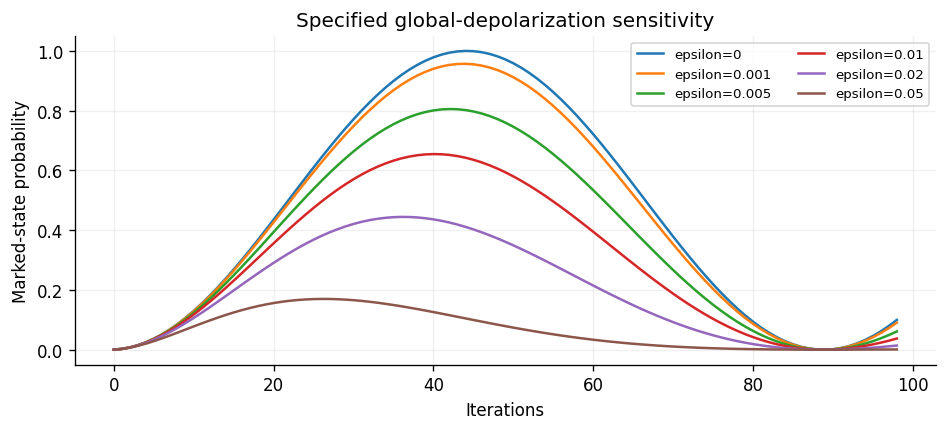

,method,normalized_cost
0,Random classical order: expected predicate calls,3196.890244
1,Ideal procedural quantum: unit-cost queries only,45.000000
2,Implemented lookup: preprocessing + quantum qu...,258093.000000


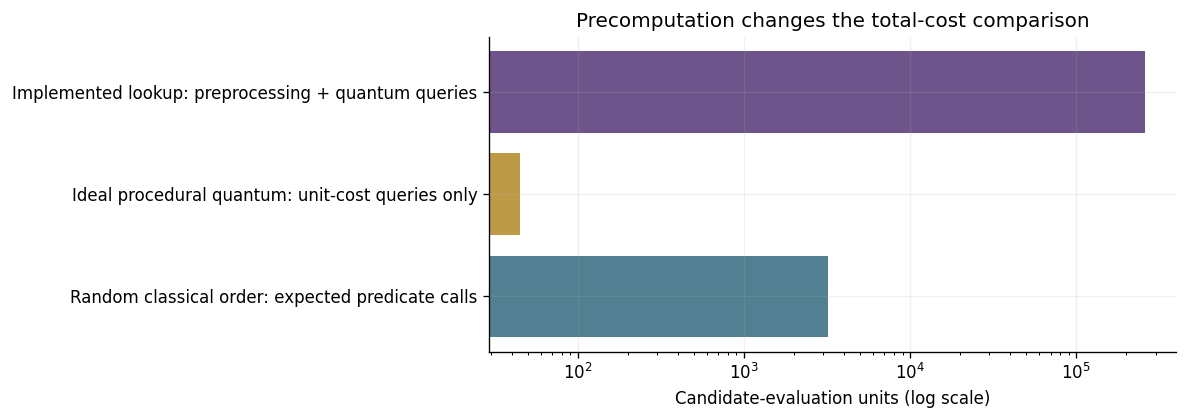

In [13]:
epsilons=[0,.001,.005,.01,.02,.05]
noise_rows=[]
fig,ax=plt.subplots(figsize=(8,3.7))
for eps in epsilons:
    probs=(1-eps)**ks*np.array(probabilities)+(1-(1-eps)**ks)*M/N
    ax.plot(ks,probs,label=f'epsilon={eps:g}')
    opt=int(np.argmax(probs)); noise_rows.append({'epsilon_per_iterate':eps,'best_k_in_grid':opt,'best_probability':float(probs[opt]),'probability_at_ideal_k':float(probs[kstar])})
ax.set(xlabel='Iterations',ylabel='Marked-state probability',title='Specified global-depolarization sensitivity'); ax.legend(fontsize=8,ncol=2)
savefig('F09_noise_sensitivity')
pd.DataFrame(noise_rows).to_csv(OUT/'noise_sensitivity.csv',index=False)
classical_expected=(N+1)/(M+1) # random ordering without replacement, exact expectation
precompute=4**6*63
accounting=pd.DataFrame({'method':['Random classical order: expected predicate calls','Ideal procedural quantum: unit-cost queries only','Implemented lookup: preprocessing + quantum queries'],
                        'normalized_cost':[classical_expected,kstar+1,precompute+kstar+1]})
display(accounting)
accounting.to_csv(OUT/'resource_accounting.csv',index=False)
fig,ax=plt.subplots(figsize=(10,3.6)); ax.barh(accounting.method,accounting.normalized_cost,color=['#527f91','#bd9b46','#6d548b'])
ax.set_xscale('log'); ax.set(xlabel='Candidate-evaluation units (log scale)',title='Precomputation changes the total-cost comparison')
savefig('F10_total_cost_accounting')


## 11. Exploratory larger-tree search

The exact Catalan-state method becomes expensive quickly. We therefore add a seeded randomized exploration for \(n=8,16,32\), starting from a balanced tree and using length-64 sequences. Workloads include uniform, alternating extremes, concentrated hot keys, and ascending scans, each with occasional random perturbations. Random deletion masks are evaluated with the exact splay engine.

These are **sampled observations**, not upper bounds or certified maxima. Bootstrap confidence intervals would describe a sampling distribution, not certify a worst-case bound; we avoid that misleading interpretation. The cache is cleared after the exploration to limit memory retention.

,n,workload,count,mean,max
0,8,extremes,250,0.504555,1.085714
1,8,hot_keys,250,0.552444,1.000000
2,8,scan,250,0.556111,0.950450
3,8,uniform,250,0.565756,0.949153
4,16,extremes,250,0.487958,0.933333
5,16,hot_keys,250,0.585708,0.942446
6,16,scan,250,0.595217,0.958801
7,16,uniform,250,0.554979,0.926641
8,32,extremes,250,0.493822,0.982659
9,32,hot_keys,250,0.555258,0.988166


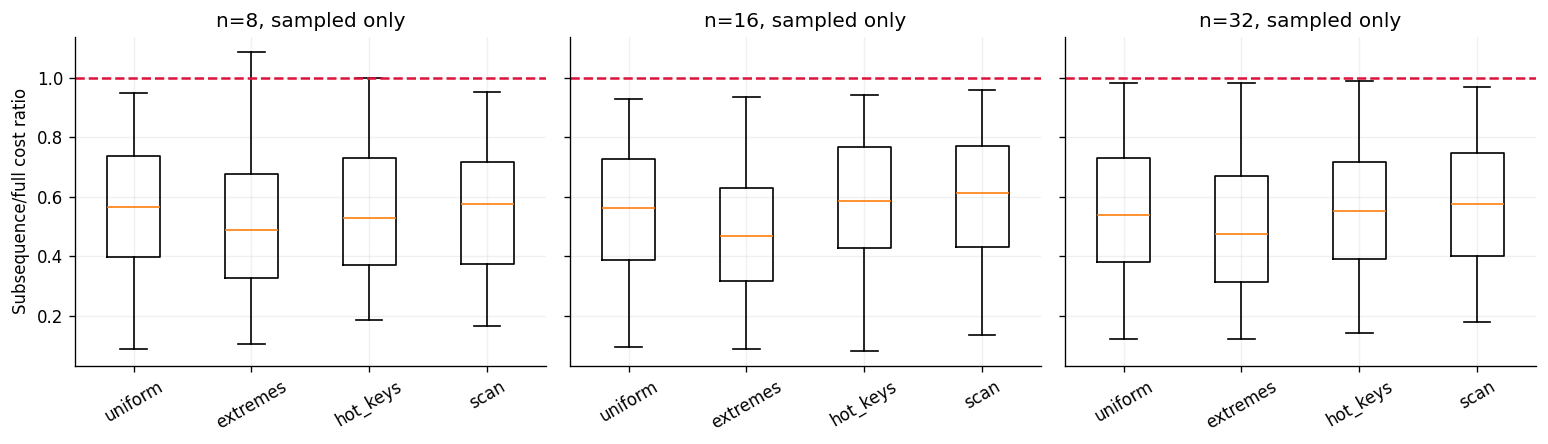

In [14]:
large_rows=[]; attempts=250
for n in (8,16,32):
    t=balanced(0,n)
    for workload in ('uniform','extremes','hot_keys','scan'):
        best_ratio=0; best_pair=None
        for rep in range(attempts):
            if workload=='uniform': seq=rng.integers(0,n,size=64)
            elif workload=='extremes': seq=np.resize(np.array([0,n-1]),64)
            elif workload=='hot_keys': seq=rng.choice(np.array([0,n//2,n-1]),size=64)
            else: seq=np.arange(64)%n
            seq=seq.copy(); change=rng.random(64)<.08; seq[change]=rng.integers(0,n,size=int(change.sum()))
            keep=rng.random(64)<rng.uniform(.2,.9); sub=seq[keep]
            a=execute(t,seq)[0]; b=execute(t,sub)[0]; ratio=b/a
            large_rows.append({'n':n,'workload':workload,'replicate':rep,'ratio':ratio,'full_cost':a,'subsequence_cost':b,'retained':int(keep.sum())})
large=pd.DataFrame(large_rows); large.to_csv(OUT/'exploratory_large_trees.csv',index=False)
large_summary=large.groupby(['n','workload']).ratio.agg(['count','mean','max']).reset_index(); display(large_summary)
fig,axes=plt.subplots(1,3,figsize=(13,3.8),sharey=True)
for ax,n in zip(axes,(8,16,32)):
    labels=['uniform','extremes','hot_keys','scan']
    ax.boxplot([large.loc[(large.n==n)&(large.workload==w),'ratio'] for w in labels],tick_labels=labels)
    ax.tick_params(axis='x',rotation=30); ax.axhline(1,ls='--',color='crimson'); ax.set_title(f'n={n}, sampled only')
axes[0].set_ylabel('Subsequence/full cost ratio'); savefig('F11_exploratory_workloads')
access.cache_clear()


## 12. Independent integer certificate checker and adversarial corruption test

A solver-produced certificate is useful only if it can be checked without trusting the LP. The companion `verify_certificates.py` reconstructs the labelled transitions from the splay implementation, checks that the stored graph contains exactly all reachable states and actions, checks diagonal coverage, validates every integer inequality, and verifies a matching closed cycle and reachability from a diagonal.

The notebook also deliberately corrupts a potential entry and confirms that an exact inequality check rejects it. No tolerance is used in the final proof inequalities. Trusted components remain Python integer arithmetic, the graph construction, and the validated splay implementation; this is an independently executable certificate check, **not** a Lean/Coq formalization.

In [15]:
def verify_payload(payload):
    n=payload['n']; g=build_graph(n)
    assert payload['states']==[list(s) for s in g['states']]
    assert payload['edges']==g['edges'].tolist()
    assert payload['diagonal_state_ids']==g['diagonal']
    p,q=payload['K']; assert isinstance(p,int) and isinstance(q,int) and q>0
    H=payload['H']; assert len(H)==len(g['states']) and all(type(h)==int for h in H)
    for u,v,a,b,x,d in payload['edges']:
        assert H[v]-H[u] >= q*b-p*a
    cyc=payload['cycle_edge_ids']; assert cyc
    first=payload['edges'][cyc[0]][0]; state=first; A=B=0
    for eid in cyc:
        u,v,a,b,x,d=payload['edges'][eid]; assert u==state
        A+=a; B+=b; state=v
    assert state==first and q*B==p*A and A>0
    prefix,diag=prefix_to(g,first); assert diag in g['diagonal']
    return {'n':n,'K':str(Fraction(p,q)),'states':len(g['states']),'edges_verified':len(g['edges']),'status':'PASS'}
verified=[]
for path in sorted(OUT.glob('certificate_n*.json')):
    verified.append(verify_payload(json.loads(path.read_text())))
display(pd.DataFrame(verified))
payload=json.loads((OUT/'certificate_n4.json').read_text())
# Increase H at a source of a non-self edge enough to break that inequality.
e=next(e for e in payload['edges'] if e[0]!=e[1]); payload['H'][e[0]]+=10**9
try:
    verify_payload(payload)
except AssertionError:
    print('PASS: deliberately corrupted certificate was rejected.')
else:
    raise AssertionError('Corruption should have been detected')


PASS: deliberately corrupted certificate was rejected.


,n,K,states,edges_verified,status
0,1,1,1,2,PASS
1,2,1,4,16,PASS
2,3,1,19,114,PASS
3,4,3/2,196,1568,PASS
4,5,8/5,1764,17640,PASS


## 13. Structural potential discovery with exact certification

The main research contribution is the **certificate-producing framework**: an upper-bound certificate, a matching repeatable witness where available, and an executable checker. Quantum search is an experimental discovery component.

State-table potentials from Section 4 assign one value to each paired state. We now learn a compact structural expression
\[
 \Phi_c(T_X,T_Y)=\sum_{j=1}^{18}c_j f_j(T_X,T_Y),
\]
using one rational coefficient vector across every evaluated size.

The integer-valued features include total depths, squared depths, squared subtree sizes, integer subtree ranks, leaf counts and subtree imbalance in each tree; plus differences in depths and subtree sizes, disagreements in ancestor and parent relationships, root separation, and root equality. The integer rank is \(\lfloor\log_2 |T_v|\rfloor\). The feature bank is fixed before fitting.

**Protocol:** fit on sizes 1–4; freeze; verify every reachable edge at size 5; record any failure; refine using sizes 1–5; freeze again; build and verify unseen size 6. Size 5 was previously used in the separate state-table analysis, but is excluded from initial structural-template fitting. Size 6 is built only after the refined formula is frozen. This is an algorithmic transfer test, not a preregistered statistical study. Held-out failures remain exported counterexamples.

For an edge \(e:u\to v\), require
\[
 b_e-Ka_e+[f(v)-f(u)]^Tc\le0.
\]
An LP minimizes \(K\) over active constraints. A separation scan finds violating transitions, adds the worst 32, and refits. A second LP minimizes \(\|c\|_1\) to encourage a compact formula at the fitted coefficient. L1 sparsity does not guarantee the fewest nonzero terms.

**Finite-training guarantee:** in exact arithmetic, each nonterminal iteration adds a new violated constraint, so at most \(|E_{train}|\) additions rounds are needed. A fully feasible active-set optimum is also optimal for the finite full-template LP: its relaxation gives a lower bound and its feasible solution gives an upper bound. Our numerical discovery does not itself certify this optimum. After rational reconstruction, we recompute the coefficient required by that exact formula and verify all training edges with Python integer arithmetic.

**Certificate theorem:** if every edge passes at a specified size,
\[
 C_T(Y)\le K C_T(X)+\Phi_c(T,T)-\Phi_c(T_X^f,T_Y^f)
 \le K C_T(X)+B_{n,T},
\quad B_{n,T}=\Phi_c(T,T)-\min_s\Phi_c(s).
\]
This proves an all-length result only for each graph actually checked. A structural formula can be less sharp than the unrestricted state-table optimum. Matching lower cycles from Section 5 certify the state-table coefficients, not automatically the learned formula's coefficient.

In [16]:
FEATURE_NAMES=[
 'depth_sum_X','depth_sum_Y','depth_square_sum_X','depth_square_sum_Y',
 'subtree_square_sum_X','subtree_square_sum_Y','integer_rank_sum_X','integer_rank_sum_Y',
 'leaf_count_X','leaf_count_Y','imbalance_sum_X','imbalance_sum_Y',
 'depth_absolute_difference','subtree_absolute_difference','ancestor_disagreement',
 'parent_disagreement','root_gap','same_root']

@lru_cache(None)
def tree_statistics(t):
    n=len(inorder(t)); depths=np.zeros(n,dtype=np.int64); sizes=np.zeros(n,dtype=np.int64)
    parents=np.full(n,-1,dtype=np.int64); ancestors=np.zeros((n,n),dtype=bool)
    leaves=0; imbalance=0
    def walk(z,depth=0,parent=-1,path=()):
        nonlocal leaves,imbalance
        if z is None:return 0
        k,l,r=z; depths[k]=depth; parents[k]=parent
        for a in path:ancestors[a,k]=True
        ls=walk(l,depth+1,k,path+(k,)); rs=walk(r,depth+1,k,path+(k,))
        sizes[k]=1+ls+rs; leaves+=int(l is None and r is None); imbalance+=abs(ls-rs)
        return int(sizes[k])
    walk(t)
    stats=(int(depths.sum()),int(depths@depths),int(sizes@sizes),
           sum(int(z).bit_length()-1 for z in sizes),leaves,imbalance)
    return depths,sizes,parents,ancestors,stats

def structural_features(tx,ty):
    dx,sx,px,ax,fx=tree_statistics(tx); dy,sy,py,ay,fy=tree_statistics(ty)
    paired=[v for pair in zip(fx,fy) for v in pair]
    paired += [int(np.abs(dx-dy).sum()),int(np.abs(sx-sy).sum()),int(np.count_nonzero(ax!=ay)),
               int(np.count_nonzero(px!=py)),abs(tx[0]-ty[0]),int(tx[0]==ty[0])]
    return np.array(paired,dtype=np.int64)

def feature_table(g):
    return np.array([structural_features(g['trees'][i],g['trees'][j]) for i,j in g['states']],dtype=np.int64)

def feature_problem(graphs,ns):
    differences=[]; aa=[]; bb=[]; labels=[]
    for n in ns:
        g=graphs[n]; F=feature_table(g); E=g['edges']
        differences.append(F[E[:,1]]-F[E[:,0]])
        aa.append(E[:,2]); bb.append(E[:,3])
        labels.extend((n,eid) for eid in range(len(E)))
    return np.vstack(differences),np.concatenate(aa),np.concatenate(bb),labels

def propose_structural(D,a,b,chosen):
    ix=np.array(sorted(chosen),dtype=int); d=D.shape[1]
    A=np.column_stack([-a[ix],D[ix]])
    obj=np.zeros(d+1);obj[0]=1
    fit=linprog(obj,A_ub=A,b_ub=-b[ix],bounds=[(0,None)]+[(None,None)]*d,method='highs')
    if not fit.success:raise RuntimeError(fit.message)
    return float(fit.x[0]),fit.x[1:]

def sparse_formula(D,a,b,Kfloat):
    d=D.shape[1]
    fit=linprog(np.ones(2*d),A_ub=np.column_stack([D,-D]),b_ub=Kfloat*a-b+1e-8,
                bounds=[(0,None)]*(2*d),method='highs')
    if not fit.success:raise RuntimeError(fit.message)
    raw=fit.x[:d]-fit.x[d:]
    coeff=[Fraction(0) if abs(c)<1e-7 else Fraction(float(c)).limit_denominator(1_000) for c in raw]
    L=math.lcm(*(c.denominator for c in coeff))
    numer=np.array([c.numerator*(L//c.denominator) for c in coeff],dtype=object)
    vals=np.asarray(D,dtype=object)@numer
    # Recompute the required coefficient exactly after rational reconstruction.
    K=max(Fraction(L*int(bi)+int(vi),L*int(ai)) for ai,bi,vi in zip(a,b,vals))
    return K,coeff

def check_structural(g,K,coeff,F=None):
    F=feature_table(g) if F is None else F
    E=g['edges']; L=math.lcm(K.denominator,*(c.denominator for c in coeff))
    cn=np.array([c.numerator*(L//c.denominator) for c in coeff],dtype=object)
    P=np.asarray(F,dtype=object)@cn
    kn=K.numerator*(L//K.denominator)
    residual=L*np.asarray(E[:,3],dtype=object)-kn*np.asarray(E[:,2],dtype=object)+P[E[:,1]]-P[E[:,0]]
    bad=np.flatnonzero(np.array([int(z)>0 for z in residual]))
    return {'passed':len(bad)==0,'bad_edges':bad,'residual':residual,'potential_numerators':P,
            'scale':L,'max_residual':Fraction(int(max(residual)),L)}

def learn_structural(graphs,ns,seed):
    D,a,b,labels=feature_problem(graphs,ns)
    local_rng=np.random.default_rng(seed)
    chosen=set(local_rng.choice(len(a),size=min(32,len(a)),replace=False).tolist())
    records=[]
    for iteration in range(len(a)+1):
        K,c=propose_structural(D,a,b,chosen)
        residual=b-K*a+D@c; bad=np.flatnonzero(residual>1e-7)
        records.append({'training_sizes':str(tuple(ns)),'iteration':iteration,'active_constraints':len(chosen),
                        'proposed_K':K,'violations':len(bad),'largest_residual':float(residual.max())})
        if len(bad)==0:break
        worst=bad[np.argsort(residual[bad])[-min(32,len(bad)):]]
        before=len(chosen);chosen.update(worst.tolist());assert len(chosen)>before
    else:raise RuntimeError('Structural refinement did not terminate')
    Kexact,coeff=sparse_formula(D,a,b,K)
    for n in ns:assert check_structural(graphs[n],Kexact,coeff)['passed']
    return Kexact,coeff,pd.DataFrame(records)

def structural_payload(g,K,coeff,stage):
    check=check_structural(g,K,coeff); E=g['edges']; P=check['potential_numerators']; L=check['scale']
    B=max(Fraction(int(P[s]-min(P)),L) for s in g['diagonal'])
    worst=int(np.argmax(check['residual']))
    u,v,a,b,x,d=map(int,E[worst]); i,j=g['states'][u]
    prefix,diag=prefix_to(g,u)
    initial_index=g['states'][diag][0]
    witness={'prefix_actions':E[prefix,4:6].tolist(),'initial_tree':g['trees'][initial_index],
             'edge_id':worst,'full_tree':g['trees'][i],'subsequence_tree':g['trees'][j],
             'key':x,'keep':d,'a':a,'b':b,'residual':str(check['max_residual'])}
    return {'stage':stage,'n':g['n'],'K':[K.numerator,K.denominator],
            'feature_names':FEATURE_NAMES,'coefficients':[[c.numerator,c.denominator] for c in coeff],
            'passed':bool(check['passed']),'violation_count':len(check['bad_edges']),
            'max_residual':str(check['max_residual']),
            'B_max_if_passed':str(B) if check['passed'] else None,'worst_edge':witness,
            'cost_model':'bottom-up splay; pre-access depth plus one'}

def verify_structural_payload(payload,g=None):
    assert payload['feature_names']==FEATURE_NAMES
    g=build_graph(payload['n']) if g is None else g
    K=Fraction(*payload['K']); coeff=[Fraction(*z) for z in payload['coefficients']]
    assert len(coeff)==len(FEATURE_NAMES)
    fresh=structural_payload(g,K,coeff,payload['stage'])
    for key in ('passed','violation_count','max_residual','B_max_if_passed'):
        assert fresh[key]==payload[key],key
    # JSON normalizes nested immutable tree tuples to lists.
    import json
    assert json.loads(json.dumps(fresh['worst_edge']))==payload['worst_edge']
    return {'stage':payload['stage'],'n':payload['n'],'classification':'PASS' if fresh['passed'] else 'REJECTED',
            'edges_checked':len(g['edges']),'claim_reproduced':True}


In [17]:
Ktrain,ctrain,history_train=learn_structural(GRAPHS,tuple(range(1,5)),SEED+100)
print('Frozen formula trained at sizes 1..4:',{name:str(c) for name,c in zip(FEATURE_NAMES,ctrain) if c})
print('Exact coefficient required by reconstructed formula:',Ktrain)
held5=check_structural(GRAPHS[5],Ktrain,ctrain)
print('Size-5 transfer:',{'passed':held5['passed'],'violations':len(held5['bad_edges']),'max_residual':str(held5['max_residual'])})
Krefined,crefined,history_refined=learn_structural(GRAPHS,tuple(range(1,6)),SEED+101)
print('Frozen refined formula:',{name:str(c) for name,c in zip(FEATURE_NAMES,crefined) if c})
print('Exact refined coefficient:',Krefined)
tstart=time.perf_counter();graph6=build_graph(6)
held6=check_structural(graph6,Krefined,crefined)
print('New size-6 transfer:',{'states':len(graph6['states']),'edges':len(graph6['edges']),
     'passed':held6['passed'],'violations':len(held6['bad_edges']),'max_residual':str(held6['max_residual']),
     'build_and_check_seconds':time.perf_counter()-tstart})
STRUCTURAL_GRAPHS={**GRAPHS,6:graph6}
structural_history=pd.concat([history_train.assign(stage='train_1_to_4'),history_refined.assign(stage='refine_1_to_5')],ignore_index=True)
structural_history.to_csv(OUT/'structural_refinement_history.csv',index=False)
coefficient_table=pd.DataFrame({'feature':FEATURE_NAMES,'trained':[str(c) for c in ctrain],'refined':[str(c) for c in crefined]})
display(coefficient_table.loc[(coefficient_table.trained!='0')|(coefficient_table.refined!='0')])
coefficient_table.to_csv(OUT/'structural_formula_coefficients.csv',index=False)


Frozen formula trained at sizes 1..4: {'depth_square_sum_Y': '1/34', 'subtree_square_sum_X': '-5/34', 'subtree_square_sum_Y': '-11/68', 'imbalance_sum_X': '13/34', 'imbalance_sum_Y': '1/4', 'depth_absolute_difference': '1/17', 'ancestor_disagreement': '7/17', 'root_gap': '4/17'}
Exact coefficient required by reconstructed formula: 26/17
Size-5 transfer: {'passed': False, 'violations': 352, 'max_residual': '32/17'}
Frozen refined formula: {'depth_square_sum_X': '99/448', 'depth_square_sum_Y': '5/42', 'subtree_square_sum_X': '-45/448', 'subtree_square_sum_Y': '-1/30', 'integer_rank_sum_X': '11/112', 'integer_rank_sum_Y': '-43/105', 'leaf_count_Y': '-26/105', 'imbalance_sum_X': '-247/672', 'imbalance_sum_Y': '-1/14', 'depth_absolute_difference': '-1/14', 'ancestor_disagreement': '11/21', 'parent_disagreement': '-10/21', 'root_gap': '2/7', 'same_root': '-1/3'}
Exact refined coefficient: 40/21
New size-6 transfer: {'states': 17424, 'edges': 209088, 'passed': False, 'violations': 1538, 'max_

,feature,trained,refined
2,depth_square_sum_X,0,99/448
3,depth_square_sum_Y,1/34,5/42
4,subtree_square_sum_X,-5/34,-45/448
5,subtree_square_sum_Y,-11/68,-1/30
6,integer_rank_sum_X,0,11/112
7,integer_rank_sum_Y,0,-43/105
9,leaf_count_Y,0,-26/105
10,imbalance_sum_X,13/34,-247/672
11,imbalance_sum_Y,1/4,-1/14
12,depth_absolute_difference,1/17,-1/14


### 13.1 Transfer certificates and rejection witnesses

The exact scan uses integer feature vectors and rational coefficients with a common denominator. Positive residual means a formula fails. PASS results include a finite additive allowance; FAIL results include the worst edge, its two source trees, key, retain/delete decision, costs, and rational residual. The portable checker rebuilds the graph and features, checks every edge, and reproduces each classification.

**Local failure versus global failure:** a failed transition inequality rejects this proposed potential certificate. It does not by itself refute the corresponding all-path cost bound; another potential may prove that bound. Likewise it does not refute the universal conjecture.

Both frozen formulas are scanned at sizes 1–6. A size used for refinement is labelled training thereafter. Discovery uses floating arithmetic, but the final exported classifications are checked with exact Python integers.

**Post-test calibration:** after preserving the size-6 failure, keep the learned coefficient vector fixed and increase only K to the maximum required edge ratio at size 6 (and the previous training K). This gives a new exact certificate through size 6. Size 6 is then calibration data; this repaired coefficient is not described as a held-out success.


Post-test n<=6 calibration with the SAME structural coefficients: 64/21
This is a fitted n<=6 certificate, not a successful held-out n=6 prediction.
PASS: corrupted structural classification rejected.


,stage,n,role,K_exact,K,passed,violations,maximum_residual,B_max_if_passed,nonzero_terms,classification_reproduced
0,train_1_to_4,1,training,26/17,1.529412,True,0,-0.529412,0,8,True
1,train_1_to_4,2,training,26/17,1.529412,True,0,-0.529412,0,8,True
2,train_1_to_4,3,training,26/17,1.529412,True,0,0.000000,18/17,8,True
3,train_1_to_4,4,training,26/17,1.529412,True,0,0.000000,19/17,8,True
4,train_1_to_4,5,held-out,26/17,1.529412,False,352,1.882353,None,8,True
5,train_1_to_4,6,held-out,26/17,1.529412,False,13908,4.852941,None,8,True
6,refine_1_to_5,1,training,40/21,1.904762,True,0,-0.904762,0,14,True
7,refine_1_to_5,2,training,40/21,1.904762,True,0,-0.476190,0,14,True
8,refine_1_to_5,3,training,40/21,1.904762,True,0,0.000000,17/21,14,True
9,refine_1_to_5,4,training,40/21,1.904762,True,0,0.000000,233/336,14,True


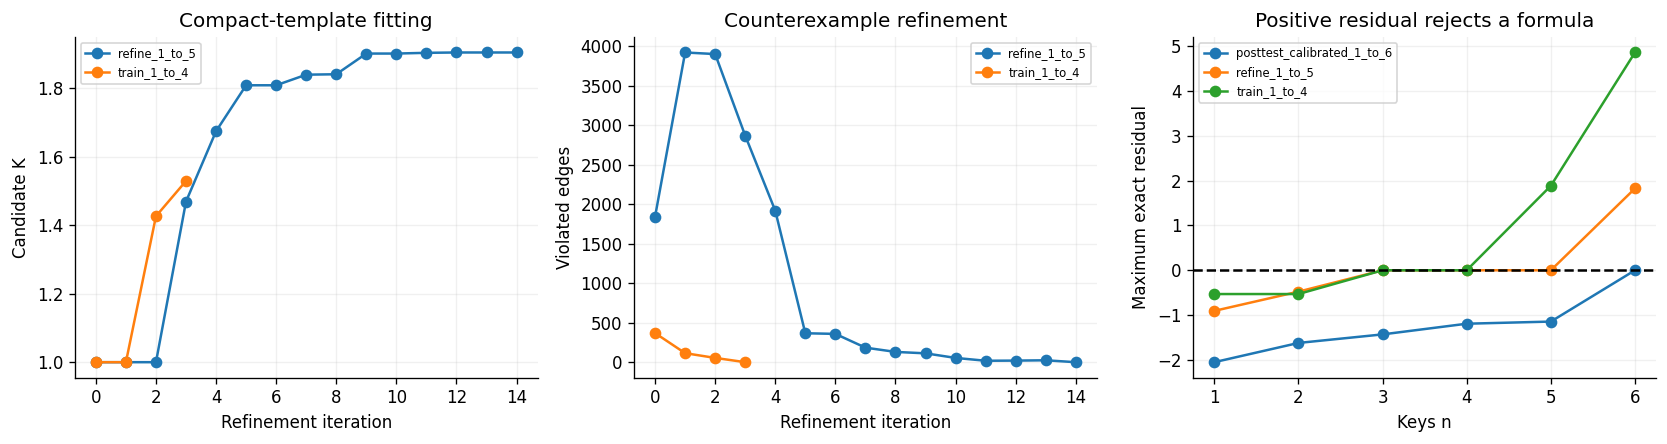

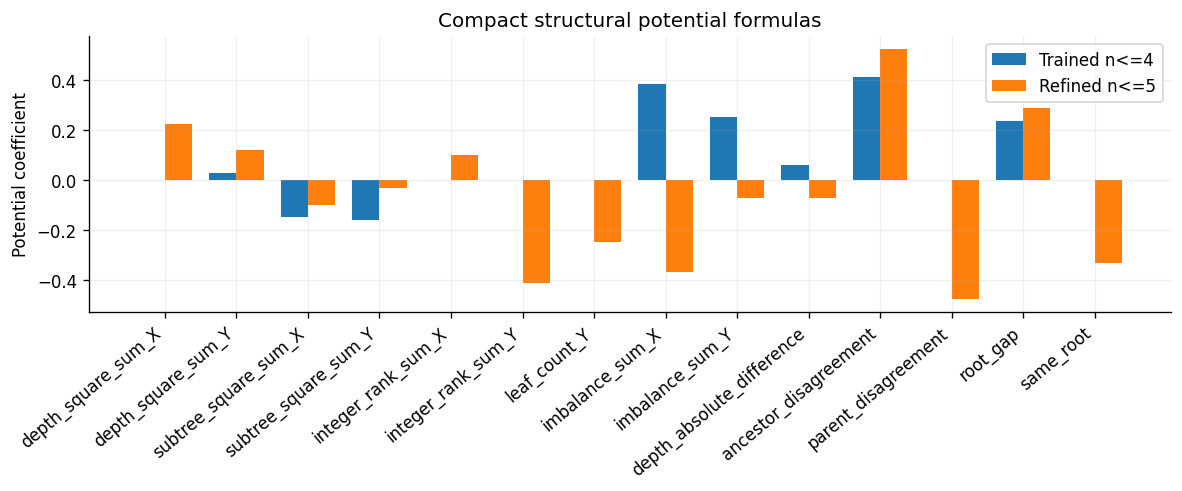

In [18]:
# Post-test calibration: keep the refined structural coefficients fixed.
# Increase K only after preserving the failed frozen n=6 outcome above.
fixed=check_structural(graph6,Krefined,crefined)
P=fixed['potential_numerators'];L=fixed['scale'];E6=graph6['edges']
Kcalibrated=max(Krefined,max(Fraction(L*int(b)+int(P[v])-int(P[u]),L*int(a))
                           for u,v,a,b,_,_ in E6))
assert check_structural(graph6,Kcalibrated,crefined)['passed']
print('Post-test n<=6 calibration with the SAME structural coefficients:',Kcalibrated)
print('This is a fitted n<=6 certificate, not a successful held-out n=6 prediction.')
structural_payloads=[];transfer_rows=[]
for stage,K,coeff,limit in [('train_1_to_4',Ktrain,ctrain,4),('refine_1_to_5',Krefined,crefined,5),('posttest_calibrated_1_to_6',Kcalibrated,crefined,6)]:
    for nn,g in STRUCTURAL_GRAPHS.items():
        payload=structural_payload(g,K,coeff,stage)
        (OUT/f'structural_{stage}_n{nn}.json').write_text(json.dumps(payload),encoding='utf-8')
        # Reparse JSON to check the portable representation as a user would.
        parsed=json.loads(json.dumps(payload))
        checked=verify_structural_payload(parsed,g)
        structural_payloads.append(payload)
        transfer_rows.append({'stage':stage,'n':nn,'role':'training' if nn<=limit else 'held-out',
            'K_exact':str(K),'K':float(K),'passed':payload['passed'],'violations':payload['violation_count'],
            'maximum_residual':float(Fraction(payload['max_residual'])),
            'B_max_if_passed':payload['B_max_if_passed'],'nonzero_terms':sum(bool(c) for c in coeff),
            'classification_reproduced':checked['claim_reproduced']})
structural_results=pd.DataFrame(transfer_rows);display(structural_results)
structural_results.to_csv(OUT/'structural_transfer_results.csv',index=False)
# Corrupting an exported classification must be detected.
corrupted=json.loads(json.dumps(structural_payloads[-1]));corrupted['passed']=not corrupted['passed']
try:verify_structural_payload(corrupted,graph6)
except AssertionError:print('PASS: corrupted structural classification rejected.')
else:raise AssertionError('Corruption was not detected')
fig,axes=plt.subplots(1,3,figsize=(14,3.8))
for stage,h in structural_history.groupby('stage'):
    axes[0].plot(h.iteration,h.proposed_K,'o-',label=stage)
    axes[1].plot(h.iteration,h.violations,'o-',label=stage)
for stage,h in structural_results.groupby('stage'):
    axes[2].plot(h.n,h.maximum_residual,'o-',label=stage)
axes[0].set(xlabel='Refinement iteration',ylabel='Candidate K',title='Compact-template fitting')
axes[1].set(xlabel='Refinement iteration',ylabel='Violated edges',title='Counterexample refinement')
axes[2].axhline(0,color='black',ls='--');axes[2].set(xlabel='Keys n',ylabel='Maximum exact residual',title='Positive residual rejects a formula')
for ax in axes:ax.legend(fontsize=7)
savefig('F13_structural_transfer')
fig,ax=plt.subplots(figsize=(10,4.2));active=[i for i,(a,b) in enumerate(zip(ctrain,crefined)) if a or b];xx=np.arange(len(active));ww=.38
ax.bar(xx-ww/2,[float(ctrain[i]) for i in active],ww,label='Trained n<=4')
ax.bar(xx+ww/2,[float(crefined[i]) for i in active],ww,label='Refined n<=5')
ax.set_xticks(xx,[FEATURE_NAMES[i] for i in active],rotation=40,ha='right')
ax.set(ylabel='Potential coefficient',title='Compact structural potential formulas');ax.legend()
savefig('F14_structural_coefficients')


### 13.2 Feature ablation against the state-table reference

To show the effect of the chosen structural representation, compare a zero potential, depth-sum features alone, and the full feature bank. All feature fits use sizes 1–4 only. Size-5 transfer remains an evaluation, not a selection criterion. The state-table optimum is a sharper but nontransferable reference with separate state values. Differences are deterministic optimization results, not statistical significance claims.

,feature_template,training_K_exact,training_K,nonzero_terms,held_n5_passed,held_n5_violations
0,zero_potential,4,4.000000,0,False,92
1,depth_sums,4,4.000000,0,False,92
2,full_feature_bank,26/17,1.529412,8,False,352


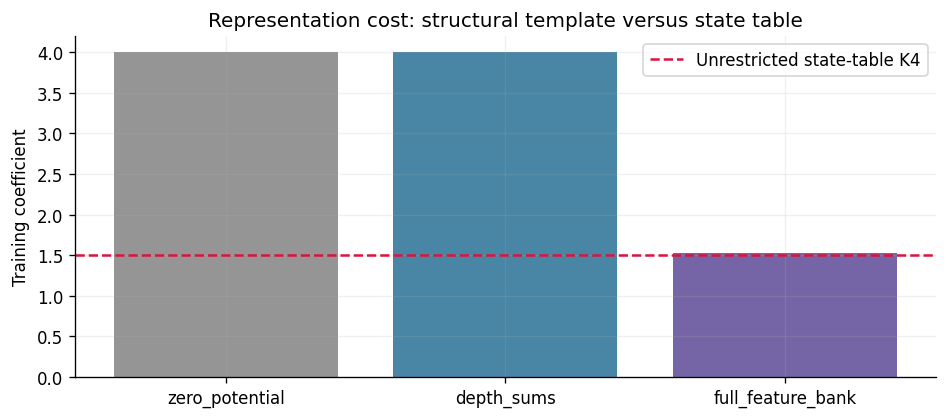

In [19]:
D,a,b,_=feature_problem(GRAPHS,tuple(range(1,5)));ablation_rows=[]
for name,subset in [('zero_potential',[]),('depth_sums',[0,1]),('full_feature_bank',list(range(len(FEATURE_NAMES))))]:
    coeff=[Fraction(0)]*len(FEATURE_NAMES)
    if subset:
        kf,_=propose_structural(D[:,subset],a,b,set(range(len(a))))
        kk,cc=sparse_formula(D[:,subset],a,b,kf)
        for idx,c in zip(subset,cc):coeff[idx]=c
    else:kk=max(Fraction(int(y),int(x)) for x,y in zip(a,b))
    for nn in range(1,5):assert check_structural(GRAPHS[nn],kk,coeff)['passed']
    hold=check_structural(GRAPHS[5],kk,coeff)
    ablation_rows.append({'feature_template':name,'training_K_exact':str(kk),'training_K':float(kk),
        'nonzero_terms':sum(bool(c) for c in coeff),'held_n5_passed':hold['passed'],
        'held_n5_violations':len(hold['bad_edges'])})
ablation=pd.DataFrame(ablation_rows);display(ablation);ablation.to_csv(OUT/'structural_feature_ablation.csv',index=False)
fig,ax=plt.subplots(figsize=(8,3.6));ax.bar(ablation.feature_template,ablation.training_K,color=['#959595','#4985a5','#7565a6'])
ax.axhline(float(CERTS[4]['K']),color='crimson',ls='--',label='Unrestricted state-table K4')
ax.set(ylabel='Training coefficient',title='Representation cost: structural template versus state table');ax.legend()
savefig('F15_structural_ablation')


### Interpretation of the measured structural results

The initial 8-term formula certifies \(K=26/17\) on sizes 1–4. At size 5 it fails on 352 transitions. This is consistent with the earlier matching cycle lower bound \(K_5=8/5\): since \(26/17<8/5\), no potential could prove that fixed coefficient at size 5 with a finite additive allowance.

Refitting through size 5 gives a 14-term formula with \(K=40/21\). It fails on 1,538 of the 209,088 size-6 transitions. This rejects that formula as a certificate; it does not prove that the underlying \(40/21\) all-path bound is impossible at size 6.

Keeping those same 14 coefficients and calibrating the scalar coefficient after inspecting size 6 gives \(K=64/21\). Exact verification then passes at every size 1–6. This is a conservative, post-test finite-size certificate; size-6 optimality is not asserted, and it is not a successful held-out prediction. All original failed outcomes and their replayable prefix/action witnesses are retained.

Feature ablation also shows a representation effect: the zero-potential and depth-sum templates require coefficient 4 on the training sizes, whereas the full feature bank requires \(26/17\). The unrestricted size-4 state-table optimum remains sharper at \(3/2\). These are distinct optimization classes.

## 14. Symbolic theorem for an arbitrary-size access family

We now give a separate, modest symbolic result for an explicitly defined infinite family. This elementary proof demonstrates the proof-producing objective; it is not claimed as a new theorem in the literature or as a consequence automatically learned by the feature-fitting code.

**Theorem (two adjacent accessed keys).** For any initial BST \(T\) on \(n\ge2\) keys, adjacent keys \(a,b\) in sorted order, any sequence \(X\) over \(\{a,b\}\), and subsequence \(Y\preceq X\),
\[
\boxed{C_T(Y)\le C_T(X)+2n-3.}
\]
The asymptotic coefficient 1 is sharp because \(Y=X\) is permitted. The additive allowance is conservative.

**Adjacency lemma.** If the root is \(a\) and the next access is its successor \(b\), the search path goes right and then only left, because \(b\) is the minimum of the right subtree. Bottom-up zig-zig rotations below the root shorten that left chain; the final step is a zig or zig-zag at the original root. The resulting root is \(b\), with \(a\) its immediate left child. For a predecessor the argument is reflected. After both keys have been accessed, repeated accesses cost 1 and switches cost 2. That root/child configuration is preserved by each switch.

Let \(m=|X|\), and let \(s(X)\) count switches between consecutive keys. Let \(d_1\) be the first access cost, and \(d_*\) the cost at the first switch, when one exists. For nonempty \(X\),
\[
 C_T(X)=m+s(X)+\alpha_T(X),\qquad
 \alpha_T(X)=d_1-1+\begin{cases}d_*-2,&s(X)>0,\\0,&s(X)=0.\end{cases}
\]
Indeed, after the first access a repetition leaves the tree unchanged; after the first switch the adjacency lemma gives the stated unit/repetition and two-unit/switch costs. Since \(d_1\le n\) and \(2\le d_*\le n\),
\[
 0\le\alpha_T(X)\le(n-1)+(n-2)=2n-3.
\]
For a sequence with no switch, \(\alpha_T(X)\le n-1\le2n-3\).

Deleting positions cannot increase the number of switches: each surviving switch spans a disjoint interval containing an original switch. Thus \(|Y|\le|X|\) and \(s(Y)\le s(X)\). The cost identity then gives
\[
 C_T(Y)-C_T(X)
 =(|Y|-|X|)+(s(Y)-s(X))+(\alpha_T(Y)-\alpha_T(X))\le2n-3.
\]
An empty subsequence is immediate, completing the proof for all sizes and lengths in this restricted family.

This structural formula has a bulk term \(m+s(X)\) and an explicitly bounded initialization remainder. It is independent of the learned finite-state potentials. It does not address access sequences over unrestricted key sets. Exhaustive and sampled checks below validate the implementation; the written proof, rather than those checks, supports the arbitrary-size statement.

**Tree-specific refinement.** Every nonempty execution has one of four initialization remainders: those of the single-key starts \((a)\), \((b)\), and the first-switch orders \((a,b)\), \((b,a)\). Set
\[
\mathcal A_T=\{C_T(a)-1,C_T(b)-1,C_T(a,b)-3,C_T(b,a)-3\},
\quad B_T=\max\mathcal A_T-\min\mathcal A_T.
\]
Then the same argument proves \(C_T(Y)\le C_T(X)+B_T\), and \(0\le B_T\le2n-3\). This is an explicit compact structural allowance obtained from four short executions, valid for arbitrary sequence lengths in the family. It is conservative, not claimed to be the smallest possible allowance.


{'adjacency_lemma_checks': 262, 'exact_cost_identities': 27540, 'deletion_checks': 73656}


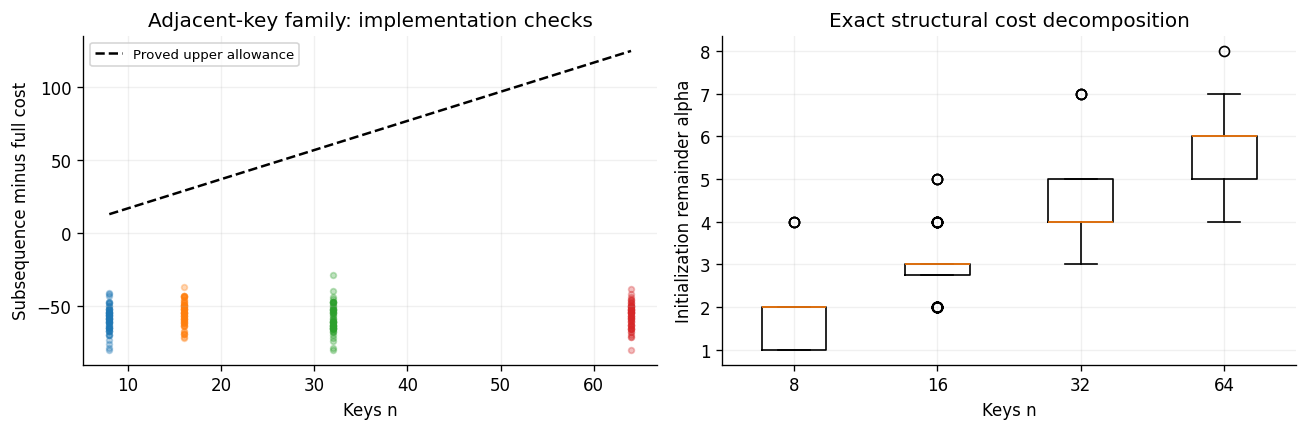

In [20]:
def switches(seq):return sum(x!=y for x,y in zip(seq,seq[1:]))
def adjacent_identity(t,seq):
    if not seq:return 0,0,0
    total,trace,_=execute(t,seq)
    first_switch=next((i for i in range(1,len(seq)) if seq[i]!=seq[i-1]),None)
    alpha=trace[0]-1+(trace[first_switch]-2 if first_switch is not None else 0)
    assert total==len(seq)+switches(seq)+alpha
    return total,alpha,switches(seq)
adjacency_checks=identity_checks=deletion_checks=0
for nn in range(2,7):
    for t in trees(0,nn):
        x=t[0]
        for y in (x-1,x+1):
            if 0<=y<nn:
                result,c=access(t,y);child=result[1] if x<y else result[2]
                assert result[0]==y and child and child[0]==x
                adjacency_checks+=1
for nn in range(2,5):
    for t in trees(0,nn):
        for aa in range(nn-1):
            for length in range(1,9):
                for bits in product((0,1),repeat=length):
                    seq=tuple(aa+b for b in bits);c,alpha,sw=adjacent_identity(t,seq)
                    assert 0<=alpha<=2*nn-3;identity_checks+=1
                    if length<=5:
                        for mask in range(1<<length):
                            sub=tuple(x for j,x in enumerate(seq) if mask>>j&1)
                            d,_,_=adjacent_identity(t,sub)
                            assert switches(sub)<=sw and d<=c+2*nn-3;deletion_checks+=1
family_check_counts={'adjacency_lemma_checks':adjacency_checks,'exact_cost_identities':identity_checks,'deletion_checks':deletion_checks}
print(family_check_counts)
def adjacent_initial_allowance(t,a):
    # Four structural initialization cases determine every nonempty execution.
    b=a+1
    alpha_cases=[execute(t,(a,))[0]-1,execute(t,(b,))[0]-1,
                 execute(t,(a,b))[0]-3,execute(t,(b,a))[0]-3]
    return max(alpha_cases)-min(alpha_cases)
family_rows=[];frng=np.random.default_rng(SEED+202)
for nn in (8,16,32,64):
    for rep in range(60):
        t=balanced(0,nn);aa=int(frng.integers(0,nn-1));seq=tuple((aa+frng.integers(0,2,size=128)).tolist())
        mask=frng.random(len(seq))<.7;sub=tuple(x for x,keep in zip(seq,mask) if keep)
        c,alpha,_=adjacent_identity(t,seq);d,_,_=adjacent_identity(t,sub)
        structural_allowance=adjacent_initial_allowance(t,aa)
        assert d-c<=structural_allowance<=2*nn-3
        family_rows.append({'n':nn,'replicate':rep,'cost_difference':d-c,'proved_additive_allowance':2*nn-3,'tree_specific_allowance':structural_allowance,'alpha_full':alpha})
family_results=pd.DataFrame(family_rows);family_results.to_csv(OUT/'symbolic_family_validation.csv',index=False)
(OUT/'symbolic_family_checks.json').write_text(json.dumps(family_check_counts,indent=2),encoding='utf-8')
fig,axes=plt.subplots(1,2,figsize=(11,3.7))
for nn,h in family_results.groupby('n'):axes[0].scatter(np.full(len(h),nn),h.cost_difference,alpha=.3,s=12)
axes[0].plot([8,16,32,64],[2*nn-3 for nn in (8,16,32,64)],'k--',label='Proved upper allowance')
axes[0].set(xlabel='Keys n',ylabel='Subsequence minus full cost',title='Adjacent-key family: implementation checks');axes[0].legend(fontsize=8)
axes[1].boxplot([family_results.loc[family_results.n==nn,'alpha_full'] for nn in (8,16,32,64)],tick_labels=[8,16,32,64])
axes[1].set(xlabel='Keys n',ylabel='Initialization remainder alpha',title='Exact structural cost decomposition')
savefig('F16_symbolic_family')


## 15. Interpretation of the extended contribution

This extension implements a rational structural formula, counterexample-guided refinement, transfer tests at larger graph sizes, exact portable checks, feature ablations, and a separate symbolic proof for a restricted infinite family.

**A rejection is useful:** failing a local transition inequality identifies where the representation or coefficients need improvement. It does not settle the unrestricted cost bound. Passing finite-size transfer does not establish a uniform theorem in the number of keys.

Approximate monotonicity [1] and automated amortized potential synthesis [2] are established techniques. The potential novelty is their splay-specific integration with paired-execution certificates, matching cycle witnesses, falsifiable structural transfer, and explicit quantum overhead accounting. Publication-level originality remains unconfirmed without a deeper prior-work comparison.

The strongest current contribution remains the certificate-producing framework, not simply the addition of Grover search. The symbolic adjacent-key theorem is included as a proof example, without claiming that it is new or was automatically discovered. A more general size-parametric potential proof remains an open research goal.

## 16. Interpretation, limitations, and next experiments

The measured coefficient \(K_n\) is the optimal **cycle/asymptotic** coefficient in the fully reachable paired-state model at size \(n\). Its upper certificate allows a finite additive term; it is not automatically the best multiplicative coefficient with zero additive allowance. The experiments cover every starting BST at the exact sizes, not just balanced trees.

The main contributions of this artifact are a reproducible graph construction, exact upper/lower certificates, action witnesses, verified symmetry reduction, and quantum accounting grounded in actual candidate predicates. Whether these constitute publishable novelty requires a broader related-work comparison.

**What remains unresolved:** a uniform \(K\) and controlled initial overhead valid for all sizes; a size-parametric potential proof; scalable non-enumerative certificates; and a reversible procedural quantum oracle with an end-to-end advantage over strong classical graph and constraint-generation baselines.

**Implemented extension:** Sections 13–15 learn structural features, preserve held-out failures, and supply a symbolic theorem for a restricted family. A uniform proof for unrestricted accesses remains unresolved.

**Not a lattice reduction:** the mirror quotient is an exact graph symmetry reduction. No lattice structure or preparation shortcut has been assumed.

## 17. References and reproducibility

1. C. C. Levy and R. E. Tarjan, *A Foundation for Proving Splay is Dynamically Optimal*, arXiv:1907.06310. https://arxiv.org/abs/1907.06310 . Related conference version: *A New Path from Splay to Dynamic Optimality*, SODA 2019, https://doi.org/10.1137/1.9781611975482.80 .
2. L. Leutgeb, G. Moser, and F. Zuleger, *ATLAS: Automated Amortised Complexity Analysis of Self-adjusting Data Structures*, CAV 2021, pp. 99–122. https://doi.org/10.1007/978-3-030-81688-9_5 .
3. L. K. Grover, *A fast quantum mechanical algorithm for database search*, STOC 1996; arXiv:quant-ph/9605043. https://arxiv.org/abs/quant-ph/9605043 .

The graph/certificate arguments above are supplied directly so the numerical claims do not depend on trusting literature summaries. Runtime values are single-run measurements on the environment recorded below; they are not universal performance claims. Quantum probabilities are ideal simulation results; no hardware calibration is implied.


In [21]:
conclusions={'exact_sizes':list(EXACT_NS),'certified_K':{str(n):str(CERTS[n]['K']) for n in EXACT_NS},
             'all_length_scope':'each exact n with finite additive overhead, all initial trees',
             'bounded_n4_m6_maximum':str(maximum),'quantum':quantum,
             'independent_checks':verified,'structural_training_K':str(Ktrain),'structural_refined_K':str(Krefined),
             'posttest_calibrated_K_n6':str(Kcalibrated),'held_out_n5_passed':bool(held5['passed']),'held_out_n6_passed':bool(held6['passed']),
             'symbolic_family':'two adjacent accessed keys; arbitrary n>=2; K=1 with allowance 2n-3','figure_count':len(FIGURES),'universal_conjecture_solved':False,
             'quantum_hardware_used':False,'quantum_end_to_end_advantage_demonstrated':False}
(OUT/'results_summary.json').write_text(json.dumps(conclusions,indent=2),encoding='utf-8')
(OUT/'environment.json').write_text(json.dumps(ENV,indent=2),encoding='utf-8')
manifest={p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in sorted(OUT.iterdir()) if p.is_file() and p.name!='manifest_sha256.json'}
(OUT/'manifest_sha256.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
display(Markdown('**Completed:** exact certificates and matching cycles for n=1..5; '+str(len(FIGURES))+' figures; all integrity checks passed; structural transfer outcomes recorded.'))
display(summary[['n','K_exact','B_max','states','edges']])


**Completed:** exact certificates and matching cycles for n=1..5; 16 figures; all integrity checks passed; structural transfer outcomes recorded.

,n,K_exact,B_max,states,edges
0,1,1,0.0,1,2
1,2,1,0.0,4,16
2,3,1,1.0,19,114
3,4,3/2,2.0,196,1568
4,5,8/5,3.0,1764,17640
